In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
# 1. Data Preparation
# Define transformations for the training and test sets
transform = transforms.Compose([
    transforms.ToTensor(),  # Convert PIL image to PyTorch Tensor 
    transforms.Normalize((0.1307,), (0.3081,))  
    ])

In [6]:
# Download and load the training and test datasets
train_dataset = datasets.MNIST(root='./data', train=True,
                               transform=transform, download=True)
test_dataset = datasets.MNIST(root='./data', train=False,
                              transform=transform, download=True)

In [7]:
# Create data loaders
# train_loader 
train_loader = DataLoader(dataset=train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=32, shuffle=False)

In [8]:
# 2. Model Construction
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.flatten = nn.Flatten()
        self.hidden = nn.Linear(28*28, 32)  # Input layer to hidden layer
        self.relu = nn.ReLU()
        self.output = nn.Linear(32, 10)     # Hidden layer to output layer
        self.softmax = nn.LogSoftmax(dim=1)  # Use LogSoftmax for numerical stability

    def forward(self, x):
        x = self.flatten(x)
        x = self.hidden(x)
        x = self.relu(x)
        x = self.output(x)
        x = self.softmax(x)
        return x

model = MLP()

In [13]:
#the number of parameters in the shallow network is 32*784+32+10*32+10=25,450
#the number of parameters in the deep network is 30*784+30+28*30+28+26*28+26+10*26+10=25442
#deep network
class DMLP(nn.Module):
    def __init__(self):
        super(DMLP, self).__init__()
        self.flatten = nn.Flatten()
        self.l1 = nn.Linear(784, 24)
        self.l2 = nn.Linear(24, 64)
        self.l3 = nn.Linear(64, 32)
        self.output = nn.Linear(32, 10)     # Hidden layer to output layer
        self.relu = nn.ReLU()
        self.softmax = nn.LogSoftmax(dim=1)  # Use LogSoftmax for numerical stability

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.l1(x))
        x = self.relu(self.l2(x))
        x = self.relu(self.l3(x))
        x = self.output(x)
        x = self.softmax(x)
        return x

deep_model = DMLP()

In [9]:
# 3. Model Compilation
criterion = nn.NLLLoss()  # Negative Log Likelihood Loss (used with LogSoftmax)

optimizer = optim.SGD(model.parameters(), lr=0.01)# lr learning rate


In [ ]:
deep_optimizer = optim.SGD(deep_model.parameters(), lr=0.01)# lr learning rate

In [6]:
# 4. Model Training
epochs = 20
train_losses = []
train_accuracy = []

In [10]:
for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    correct = 0

    for data, target in train_loader:
        optimizer.zero_grad()# clear gradient
        output = model(data)
        loss = criterion(output, target)  # target is not one-hot encoded in PyTorch one-hot
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        
        pred = output.argmax(dim=1, keepdim=True)
        correct += pred.eq(target.view_as(pred)).sum().item()

    train_losses.append(epoch_loss / len(train_loader))
    train_accuracy.append(100. * correct / len(train_loader.dataset)) 

    print(f'Epoch {epoch+1}/{epochs}, Loss: {train_losses[-1]:.4f}, Accuracy: {train_accuracy[-1]:.2f}%')

Epoch 1/20, Loss: 0.4708, Accuracy: 87.14%
Epoch 2/20, Loss: 0.2712, Accuracy: 92.18%
Epoch 3/20, Loss: 0.2235, Accuracy: 93.59%
Epoch 4/20, Loss: 0.1916, Accuracy: 94.55%
Epoch 5/20, Loss: 0.1705, Accuracy: 95.12%
Epoch 6/20, Loss: 0.1545, Accuracy: 95.61%
Epoch 7/20, Loss: 0.1428, Accuracy: 95.92%
Epoch 8/20, Loss: 0.1330, Accuracy: 96.16%
Epoch 9/20, Loss: 0.1246, Accuracy: 96.43%
Epoch 10/20, Loss: 0.1174, Accuracy: 96.59%
Epoch 11/20, Loss: 0.1117, Accuracy: 96.72%
Epoch 12/20, Loss: 0.1061, Accuracy: 96.92%
Epoch 13/20, Loss: 0.1008, Accuracy: 97.09%
Epoch 14/20, Loss: 0.0962, Accuracy: 97.24%
Epoch 15/20, Loss: 0.0920, Accuracy: 97.31%
Epoch 16/20, Loss: 0.0880, Accuracy: 97.46%
Epoch 17/20, Loss: 0.0846, Accuracy: 97.47%
Epoch 18/20, Loss: 0.0815, Accuracy: 97.65%
Epoch 19/20, Loss: 0.0783, Accuracy: 97.75%
Epoch 20/20, Loss: 0.0756, Accuracy: 97.80%


In [15]:
deep_train_losses = []
deep_train_accuracy = []

In [16]:
for epoch in range(epochs):
    deep_model.train()
    epoch_loss = 0
    correct = 0

    for data, target in train_loader:
        deep_optimizer.zero_grad()
        output = deep_model(data)
        loss = criterion(output, target)  
        loss.backward()
        deep_optimizer.step()

        epoch_loss += loss.item()
        pred = output.argmax(dim=1, keepdim=True)
        correct += pred.eq(target.view_as(pred)).sum().item()

    deep_train_losses.append(epoch_loss / len(train_loader))
    deep_train_accuracy.append(100. * correct / len(train_loader.dataset))

    print(f'Epoch {epoch+1}/{epochs}, Loss: {deep_train_losses[-1]:.4f}, Accuracy: {deep_train_accuracy[-1]:.2f}%')


Epoch 1/20, Loss: 0.7945, Accuracy: 75.34%
Epoch 2/20, Loss: 0.2793, Accuracy: 91.75%
Epoch 3/20, Loss: 0.2174, Accuracy: 93.59%
Epoch 4/20, Loss: 0.1828, Accuracy: 94.57%
Epoch 5/20, Loss: 0.1607, Accuracy: 95.28%
Epoch 6/20, Loss: 0.1445, Accuracy: 95.68%
Epoch 7/20, Loss: 0.1331, Accuracy: 96.00%
Epoch 8/20, Loss: 0.1227, Accuracy: 96.33%
Epoch 9/20, Loss: 0.1142, Accuracy: 96.59%
Epoch 10/20, Loss: 0.1063, Accuracy: 96.81%
Epoch 11/20, Loss: 0.1004, Accuracy: 97.01%
Epoch 12/20, Loss: 0.0954, Accuracy: 97.22%
Epoch 13/20, Loss: 0.0907, Accuracy: 97.23%
Epoch 14/20, Loss: 0.0862, Accuracy: 97.47%
Epoch 15/20, Loss: 0.0822, Accuracy: 97.53%
Epoch 16/20, Loss: 0.0785, Accuracy: 97.61%
Epoch 17/20, Loss: 0.0750, Accuracy: 97.71%
Epoch 18/20, Loss: 0.0714, Accuracy: 97.79%
Epoch 19/20, Loss: 0.0692, Accuracy: 97.88%
Epoch 20/20, Loss: 0.0657, Accuracy: 98.00%


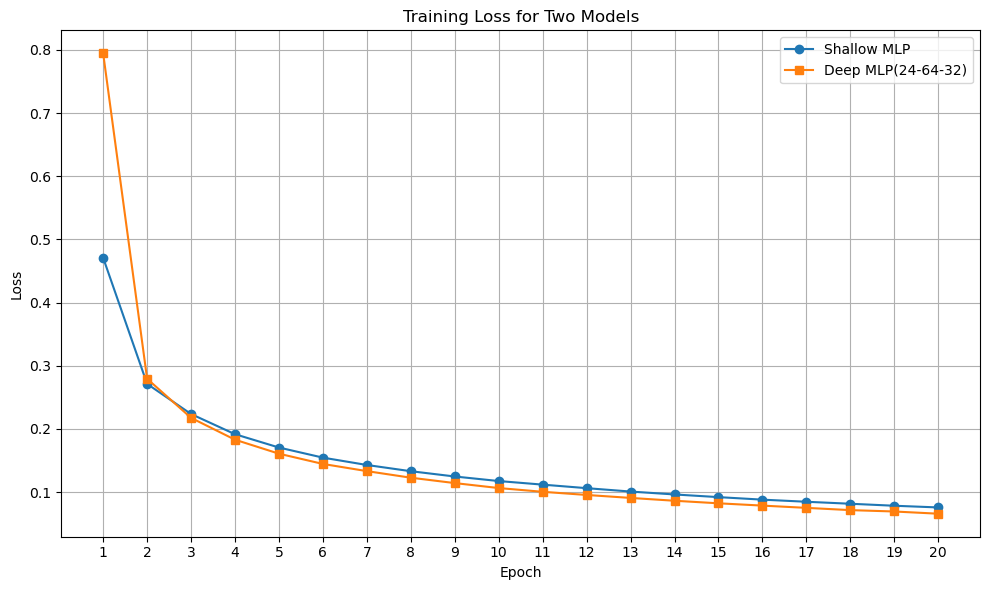

In [17]:
#compare the train process between shallow and deep network
plt.figure(figsize=(10, 6))
plt.plot(list(range(1, epochs+1)), train_losses, label='Shallow MLP', marker='o')
plt.plot(list(range(1, epochs+1)), deep_train_losses, label='Deep MLP(24-64-32)', marker='s')
plt.xticks(range(1, epochs+1))  
plt.title('Training Loss for Two Models')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [10]:
import sys
sys.path.append('./ultimate-utils-master/py_src/uutils/torch_uu/dataloaders')
sys.path.append('./ultimate-utils-master/py_src')
from mnist import get_train_valid_loader


In [40]:
train_loader, val_loader = get_train_valid_loader(
    data_path='./data',
    batch_size=16,
    batch_size_eval=16,
    seed=42,
    augment_train=False,
    val_size=0.2,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

In [42]:
epochs = 19
torch.manual_seed(42)
train_losses = [[],[],[]]
train_accuracy = [[],[],[]]
valid_losses = [[],[],[]]
valid_accuracy = [[],[],[]]
model = MLP()
learning_rates = [0.005, 0.01, 0.02]
optimizer = optim.SGD(model.parameters(), lr=0.01)# lr learning rate

In [38]:
for idx, lr in enumerate(learning_rates):
    model = MLP()
    optimizer = optim.SGD(model.parameters(), lr=lr)
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0
        epoch_loss_valid = 0
        correct = 0
        correct_valid = 0

        for data, target in train_loader:
            optimizer.zero_grad()
            output = model(data)
            loss = criterion(output, target)  
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

        train_losses[idx].append(epoch_loss / len(train_loader))
        train_accuracy[idx].append(100. * correct / len(train_loader.dataset)) 
        for data, target in val_loader:
            model.eval()
            output = model(data)
            loss = criterion(output, target)
            epoch_loss_valid += loss.item()
            pred = output.argmax(dim=1, keepdim=True)
            correct_valid += pred.eq(target.view_as(pred)).sum().item()
        valid_losses[idx].append(epoch_loss_valid / len(val_loader))
        valid_accuracy[idx].append(100. * correct_valid / len(val_loader.dataset))
        print(f'Epoch {epoch+1}/{epochs}, Loss: {train_losses[idx][-1]:.4f}, Accuracy: {train_accuracy[idx][-1]:.2f}%')
        print(f'Epoch {epoch+1}/{epochs}, Loss: {valid_losses[idx][-1]:.4f}, Accuracy: {valid_accuracy[idx][-1]:.2f}%')

Epoch 1/20, Loss: 0.6753, Accuracy: 82.49%
Epoch 1/20, Loss: 0.3745, Accuracy: 89.47%
Epoch 2/20, Loss: 0.3372, Accuracy: 90.34%
Epoch 2/20, Loss: 0.3085, Accuracy: 91.28%
Epoch 3/20, Loss: 0.2922, Accuracy: 91.55%
Epoch 3/20, Loss: 0.2792, Accuracy: 91.96%
Epoch 4/20, Loss: 0.2640, Accuracy: 92.34%
Epoch 4/20, Loss: 0.2588, Accuracy: 92.54%
Epoch 5/20, Loss: 0.2419, Accuracy: 93.02%
Epoch 5/20, Loss: 0.2384, Accuracy: 93.39%
Epoch 6/20, Loss: 0.2238, Accuracy: 93.59%
Epoch 6/20, Loss: 0.2254, Accuracy: 93.62%
Epoch 7/20, Loss: 0.2079, Accuracy: 94.08%
Epoch 7/20, Loss: 0.2111, Accuracy: 94.04%
Epoch 8/20, Loss: 0.1944, Accuracy: 94.45%
Epoch 8/20, Loss: 0.1994, Accuracy: 94.29%
Epoch 9/20, Loss: 0.1829, Accuracy: 94.79%
Epoch 9/20, Loss: 0.1911, Accuracy: 94.48%
Epoch 10/20, Loss: 0.1729, Accuracy: 95.05%
Epoch 10/20, Loss: 0.1820, Accuracy: 94.71%
Epoch 11/20, Loss: 0.1636, Accuracy: 95.33%
Epoch 11/20, Loss: 0.1758, Accuracy: 94.88%
Epoch 12/20, Loss: 0.1558, Accuracy: 95.55%
Epoch 

In [43]:
for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    epoch_loss_valid = 0
    correct = 0
    correct_valid = 0

    for data, target in train_loader:
        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)  
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        pred = output.argmax(dim=1, keepdim=True)
        correct += pred.eq(target.view_as(pred)).sum().item()

    train_losses.append(epoch_loss / len(train_loader))
    train_accuracy.append(100. * correct / len(train_loader.dataset)) 
    for data, target in val_loader:
        output = model(data)
        loss = criterion(output, target)
        epoch_loss_valid += loss.item()
        pred = output.argmax(dim=1, keepdim=True)
        correct_valid += pred.eq(target.view_as(pred)).sum().item()
    valid_losses.append(epoch_loss_valid / len(val_loader))
    valid_accuracy.append(100. * correct_valid / len(val_loader.dataset)) 

    print(f'Epoch {epoch+1}/{epochs}, Loss: {train_losses[-1]:.4f}, Accuracy: {train_accuracy[-1]:.2f}%')
    print(f'Epoch {epoch+1}/{epochs}, Loss: {valid_losses[-1]:.4f}, Accuracy: {valid_accuracy[-1]:.2f}%')


Epoch 1/19, Loss: 0.4102, Accuracy: 88.49%
Epoch 1/19, Loss: 0.2678, Accuracy: 92.23%
Epoch 2/19, Loss: 0.2319, Accuracy: 93.29%
Epoch 2/19, Loss: 0.2100, Accuracy: 93.88%
Epoch 3/19, Loss: 0.1837, Accuracy: 94.68%
Epoch 3/19, Loss: 0.1739, Accuracy: 95.00%
Epoch 4/19, Loss: 0.1548, Accuracy: 95.56%
Epoch 4/19, Loss: 0.1606, Accuracy: 95.08%
Epoch 5/19, Loss: 0.1356, Accuracy: 96.11%
Epoch 5/19, Loss: 0.1492, Accuracy: 95.78%
Epoch 6/19, Loss: 0.1219, Accuracy: 96.50%
Epoch 6/19, Loss: 0.1398, Accuracy: 95.89%
Epoch 7/19, Loss: 0.1108, Accuracy: 96.89%
Epoch 7/19, Loss: 0.1350, Accuracy: 96.04%
Epoch 8/19, Loss: 0.1029, Accuracy: 97.02%
Epoch 8/19, Loss: 0.1317, Accuracy: 96.13%
Epoch 9/19, Loss: 0.0957, Accuracy: 97.27%
Epoch 9/19, Loss: 0.1269, Accuracy: 96.30%
Epoch 10/19, Loss: 0.0898, Accuracy: 97.36%
Epoch 10/19, Loss: 0.1277, Accuracy: 96.35%
Epoch 11/19, Loss: 0.0848, Accuracy: 97.59%
Epoch 11/19, Loss: 0.1301, Accuracy: 96.29%
Epoch 12/19, Loss: 0.0797, Accuracy: 97.71%
Epoch 

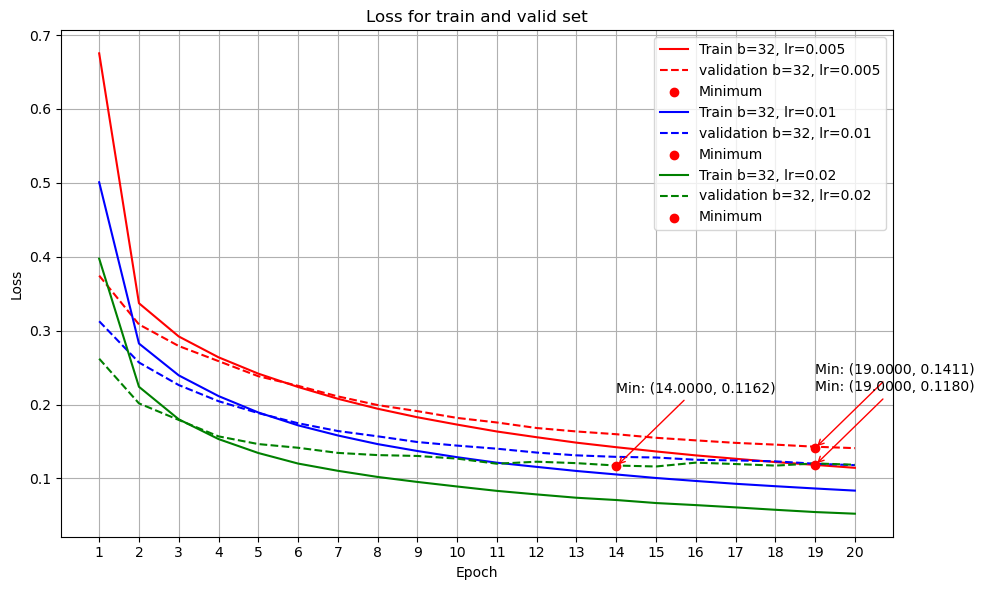

In [39]:
#compare the train process between shallow and deep network
plt.figure(figsize=(10, 6))
colors = ['red', 'blue', 'green']
batch_size = 32
for i in range(len(learning_rates)):
    min_idx = np.argmin(valid_losses[i])
    y_min = valid_losses[i][min_idx]
   
    plt.plot(list(range(1, epochs+1)), train_losses[i], color=colors[i], label=f'Train b={batch_size}, lr={learning_rates[i]}')
    plt.plot(list(range(1, epochs+1)), valid_losses[i], '--',color=colors[i], label=f'validation b={batch_size}, lr={learning_rates[i]}')
    plt.scatter(min_idx, y_min, color='red', label='Minimum', zorder=5)
    plt.annotate(f'Min: ({min_idx:.4f}, {y_min:.4f})',
             xy=(min_idx, y_min),
             xytext=(min_idx, y_min+0.1),
             arrowprops=dict(arrowstyle='->', color='red'),
             fontsize=10)
plt.xticks(range(1, epochs+1))  
plt.title('Loss for train and valid set')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [44]:
# 5. Model Evaluation
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
model.eval()
test_loss = 0
correct = 0
all_preds = []
all_targets = []
images = []

with torch.no_grad():
    for data, target in test_loader:
        output = model(data)
        test_loss += criterion(output, target).item()
        pred = output.argmax(dim=1, keepdim=True)
        correct += pred.eq(target.view_as(pred)).sum().item()
        all_preds.extend(pred.numpy())
        all_targets.extend(target.numpy())
        images.extend(data)

test_loss /= len(test_loader)
test_accuracy = 100. * correct / len(test_loader.dataset)
cm = confusion_matrix(all_targets,all_preds)
print(f'Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%')
print('confusion_matrix:  \n',cm)

Test Loss: 0.1111, Test Accuracy: 96.67%
confusion_matrix:  
 [[ 967    0    1    2    1    1    4    1    2    1]
 [   0 1121    3    1    0    1    4    2    3    0]
 [   7    3  995    3    3    0    4    8    8    1]
 [   1    2    8  976    1    2    0    4    6   10]
 [   1    0    3    1  954    0    9    1    0   13]
 [   6    1    0   20    3  835   13    1    4    9]
 [   5    3    4    1    5    2  933    1    4    0]
 [   1    7   12    4    1    0    0  984    6   13]
 [   4    0    3    5    3    5    9    7  935    3]
 [   2    7    0    5   16    5    0    3    4  967]]


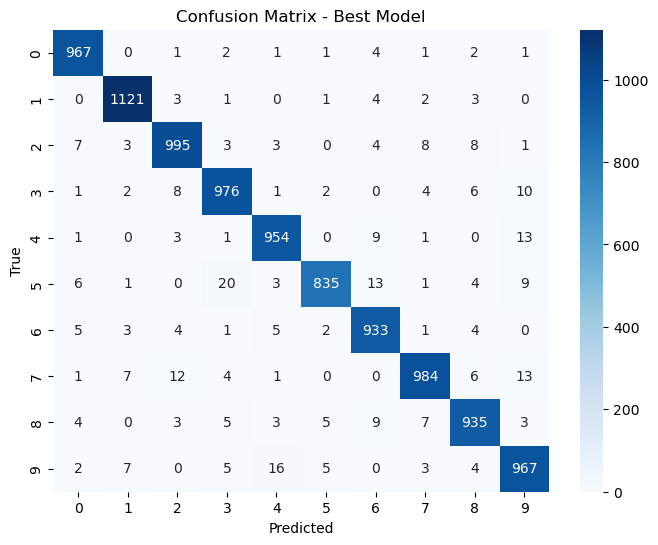

In [45]:
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - Best Model")
plt.show()

In [46]:
print('classification_report:  \n', classification_report(all_targets,all_preds))

classification_report:  
               precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.98      0.99      0.98      1135
           2       0.97      0.96      0.97      1032
           3       0.96      0.97      0.96      1010
           4       0.97      0.97      0.97       982
           5       0.98      0.94      0.96       892
           6       0.96      0.97      0.96       958
           7       0.97      0.96      0.96      1028
           8       0.96      0.96      0.96       974
           9       0.95      0.96      0.95      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



In [47]:
#9 4,   7  9,
def show_prediction(index):
    img = images[index].squeeze()  
    plt.imshow(img, cmap='gray')
    plt.title(f"Predicted: {all_preds[index]}, True: {all_targets[index]}")
    plt.axis('off')
    plt.show()

Misclassified index 8: Predicted [6], True 5


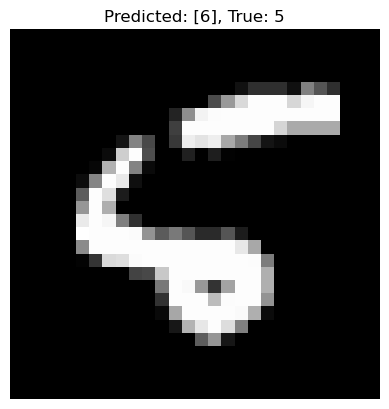

Misclassified index 241: Predicted [5], True 9


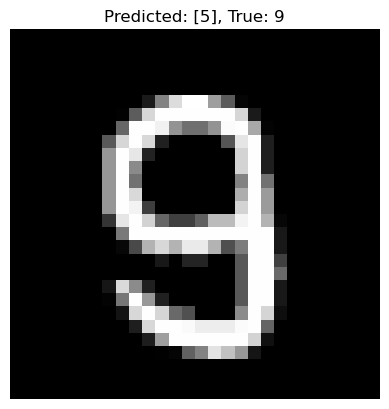

Misclassified index 247: Predicted [2], True 4


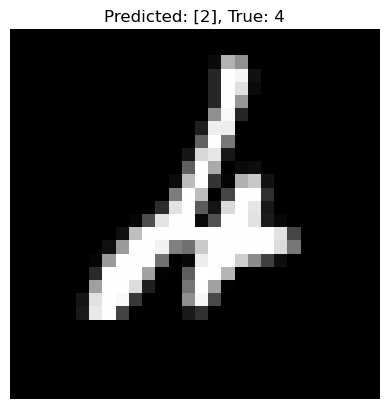

Misclassified index 320: Predicted [1], True 9


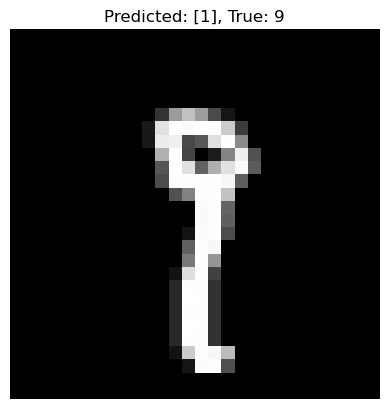

Misclassified index 321: Predicted [7], True 2


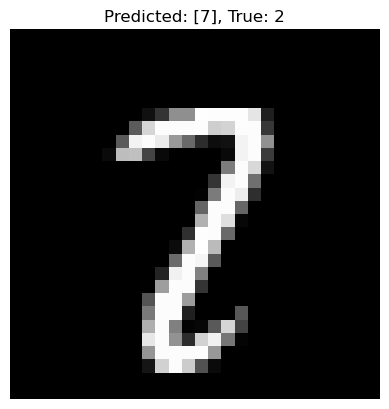

Misclassified index 340: Predicted [3], True 5


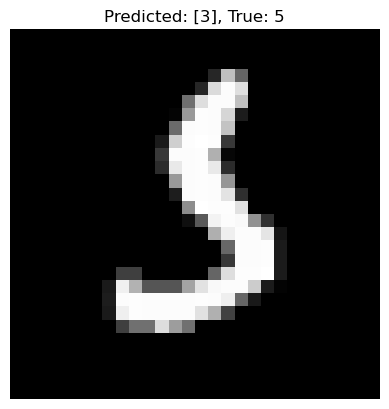

Misclassified index 381: Predicted [7], True 3


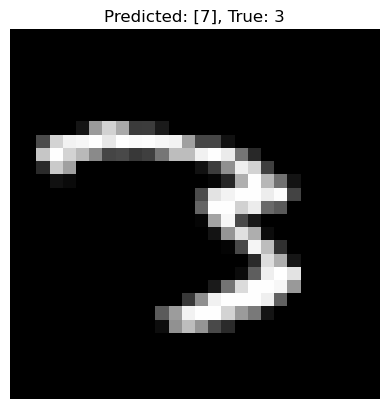

Misclassified index 445: Predicted [0], True 6


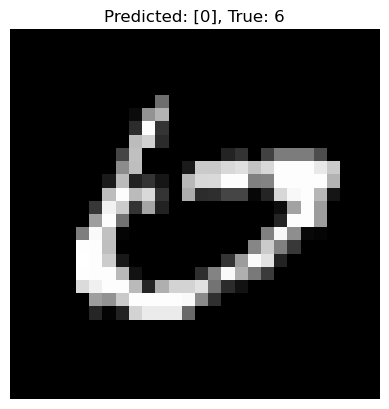

Misclassified index 495: Predicted [2], True 8


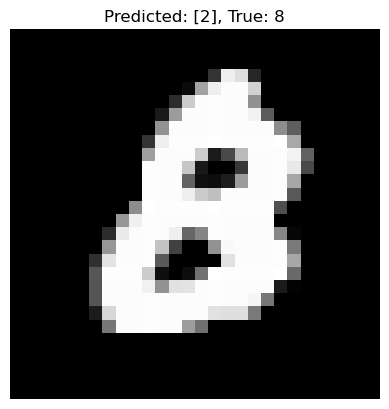

Misclassified index 582: Predicted [2], True 8


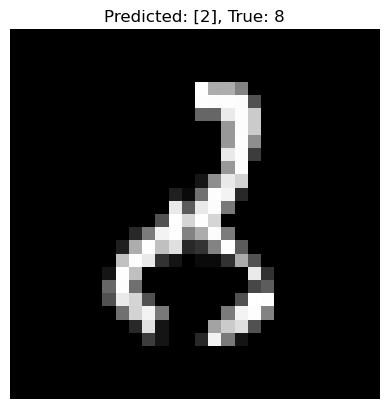

Misclassified index 583: Predicted [8], True 2


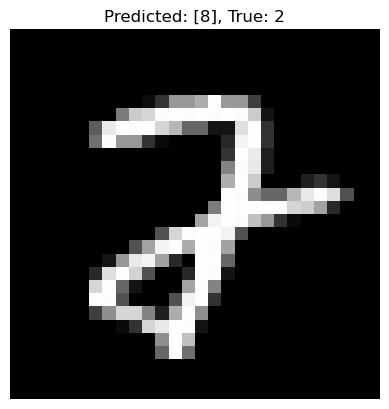

Misclassified index 610: Predicted [6], True 4


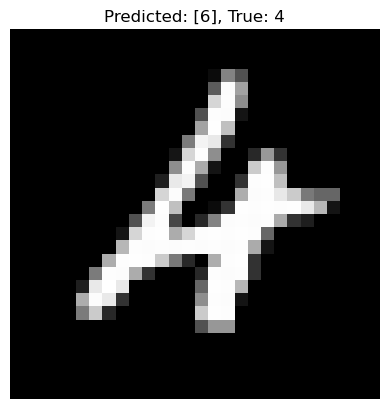

Misclassified index 619: Predicted [8], True 1


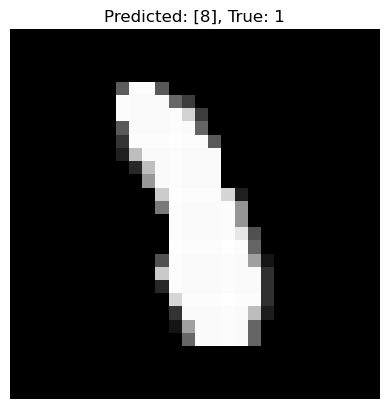

Misclassified index 628: Predicted [9], True 3


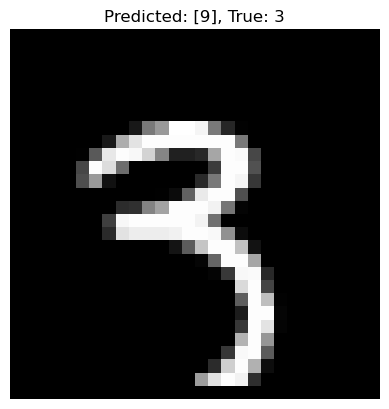

Misclassified index 629: Predicted [6], True 2


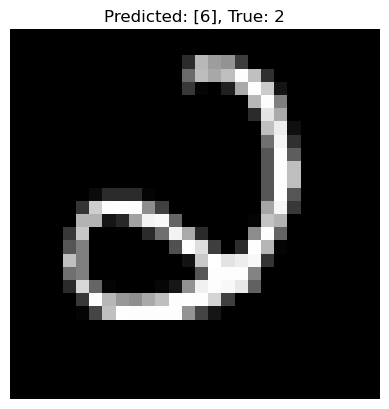

Misclassified index 684: Predicted [3], True 7


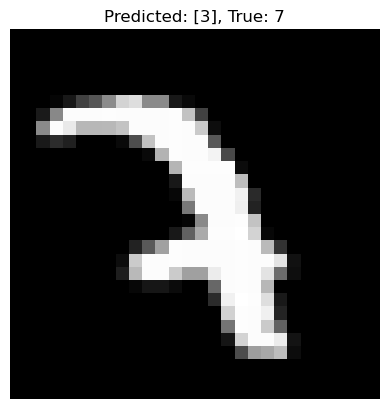

Misclassified index 691: Predicted [7], True 8


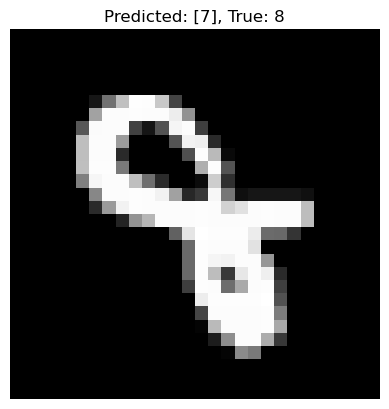

Misclassified index 716: Predicted [7], True 1


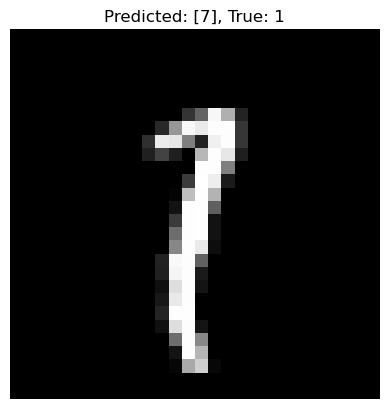

Misclassified index 717: Predicted [6], True 0


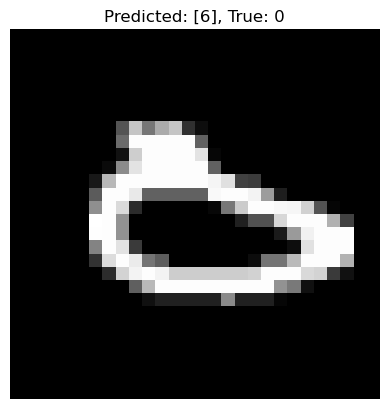

Misclassified index 740: Predicted [9], True 4


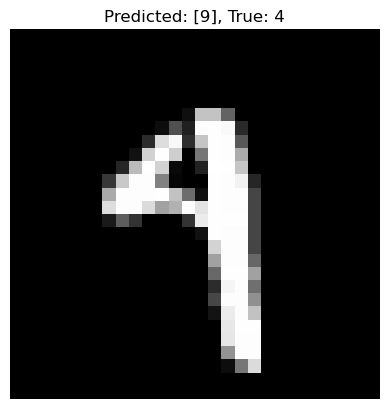

Misclassified index 844: Predicted [7], True 8


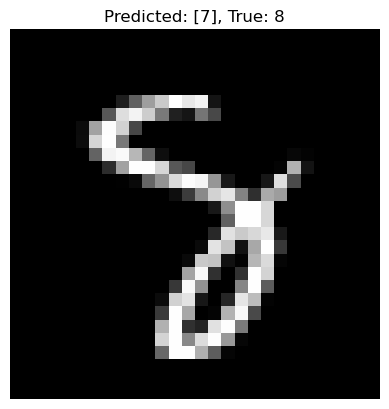

Misclassified index 877: Predicted [5], True 8


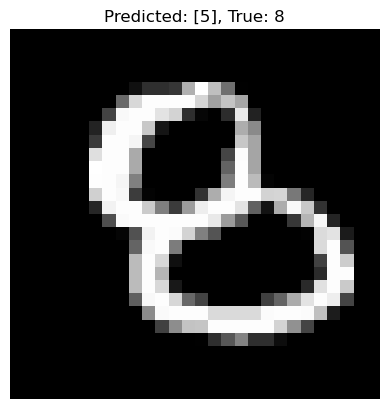

Misclassified index 881: Predicted [9], True 4


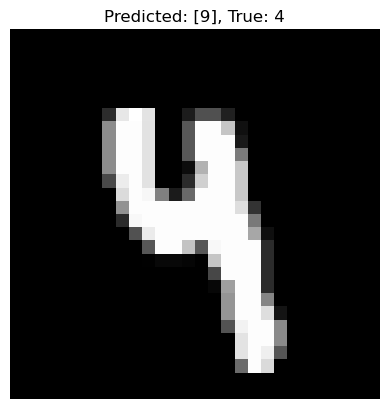

Misclassified index 924: Predicted [7], True 2


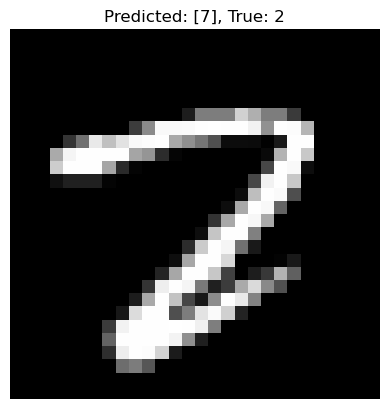

Misclassified index 944: Predicted [1], True 3


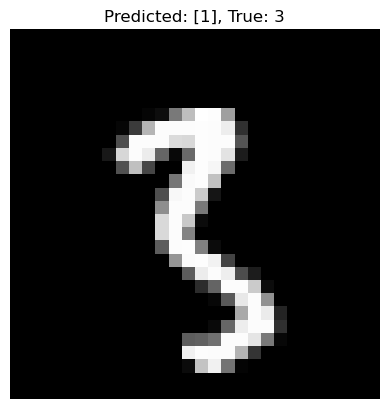

Misclassified index 950: Predicted [2], True 7


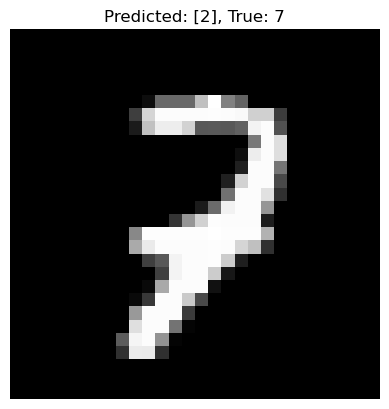

Misclassified index 951: Predicted [4], True 5


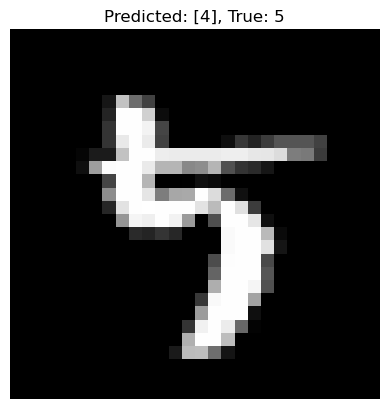

Misclassified index 956: Predicted [2], True 1


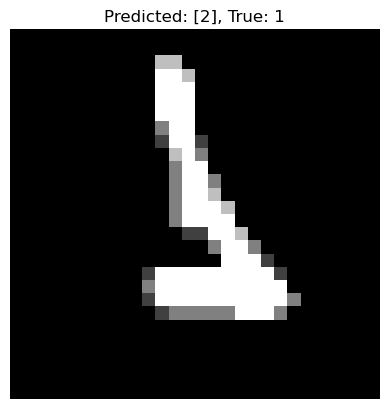

Misclassified index 965: Predicted [0], True 6


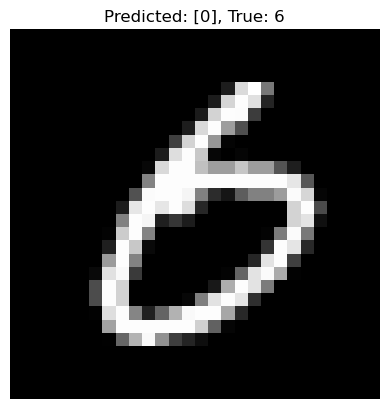

Misclassified index 1003: Predicted [3], True 5


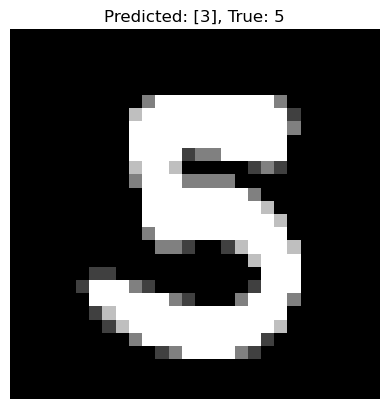

Misclassified index 1014: Predicted [5], True 6


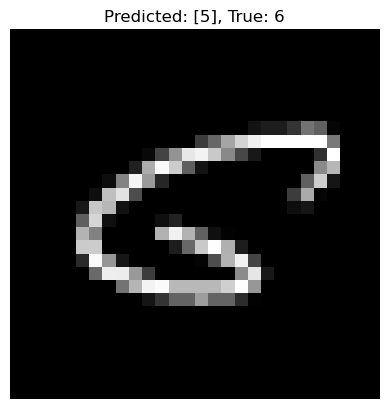

Misclassified index 1032: Predicted [8], True 5


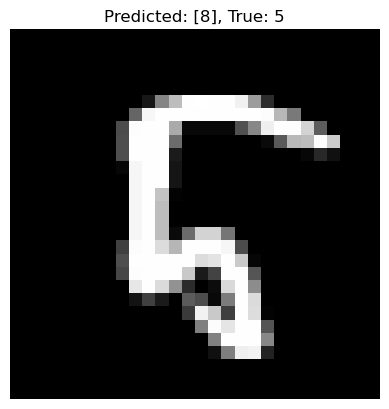

Misclassified index 1039: Predicted [9], True 7


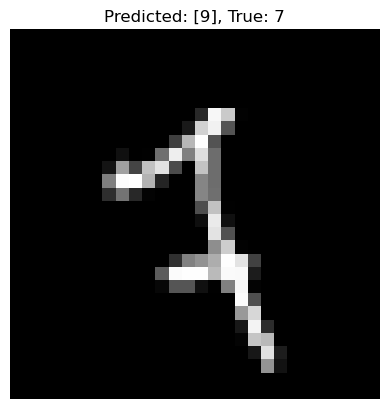

Misclassified index 1107: Predicted [3], True 9


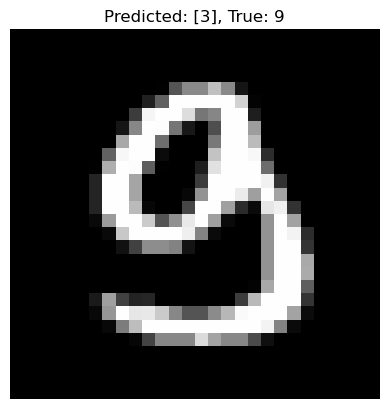

Misclassified index 1112: Predicted [6], True 4


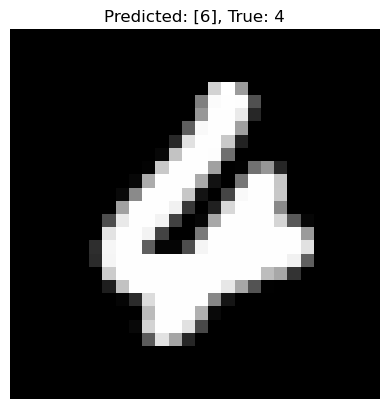

Misclassified index 1114: Predicted [8], True 3


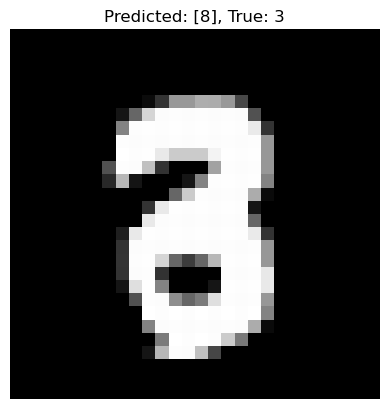

Misclassified index 1128: Predicted [7], True 3


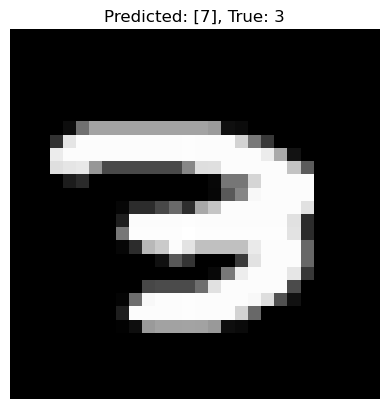

Misclassified index 1156: Predicted [8], True 7


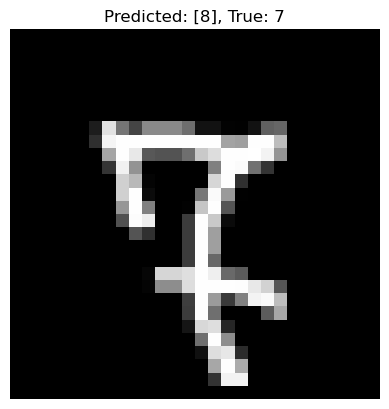

Misclassified index 1166: Predicted [5], True 3


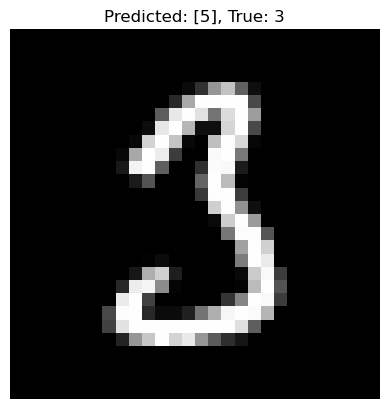

Misclassified index 1178: Predicted [6], True 4


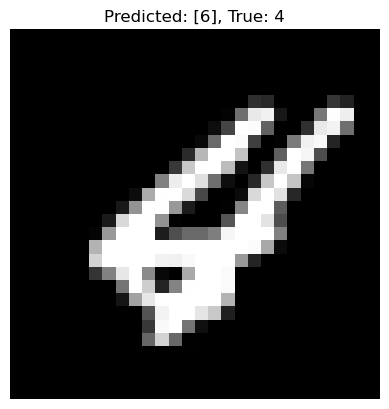

Misclassified index 1181: Predicted [1], True 6


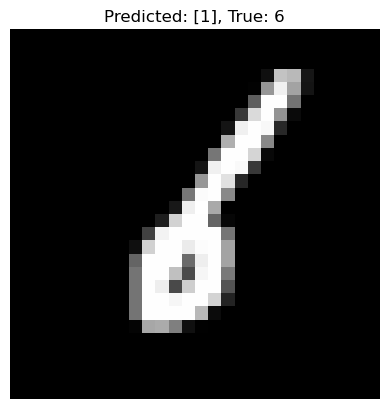

Misclassified index 1182: Predicted [8], True 6


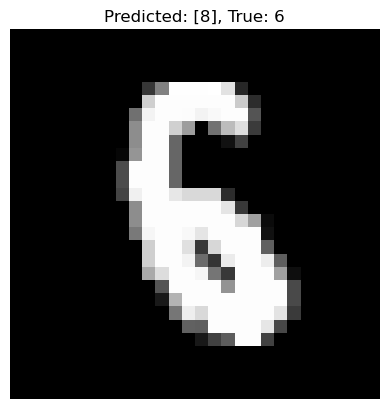

Misclassified index 1194: Predicted [9], True 7


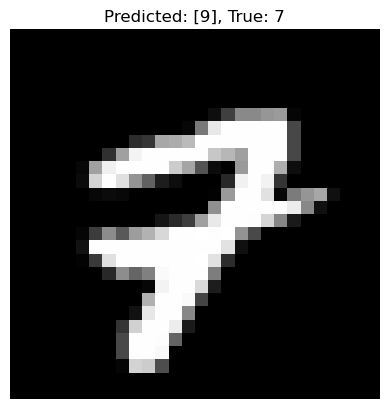

Misclassified index 1224: Predicted [6], True 2


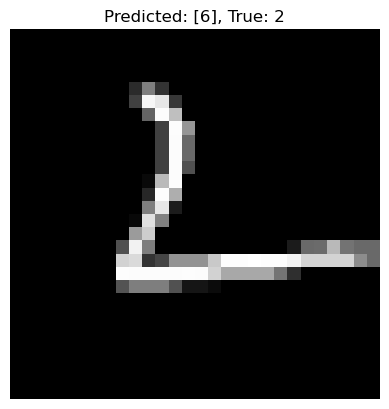

Misclassified index 1226: Predicted [2], True 7


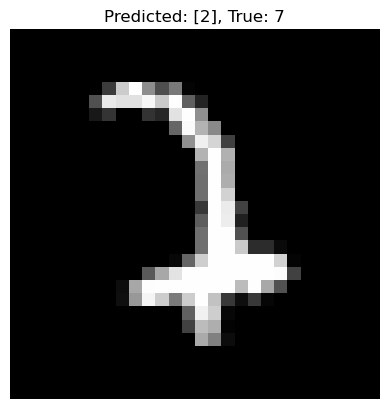

Misclassified index 1232: Predicted [4], True 9


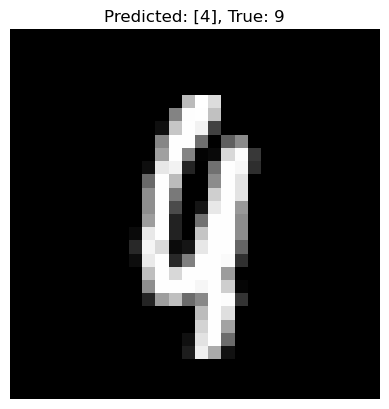

Misclassified index 1242: Predicted [9], True 4


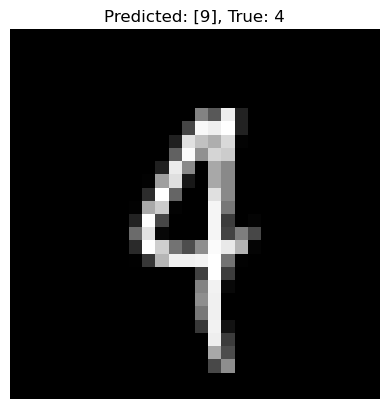

Misclassified index 1247: Predicted [5], True 9


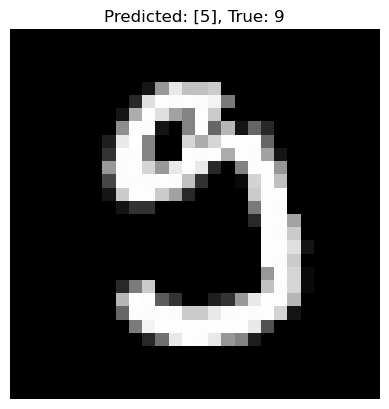

Misclassified index 1251: Predicted [1], True 2


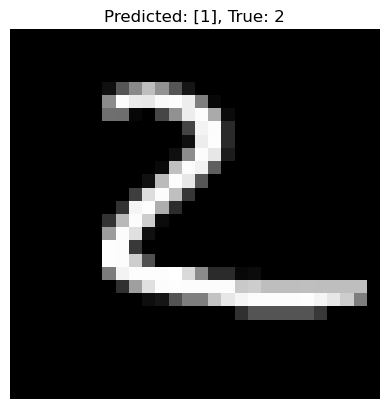

Misclassified index 1260: Predicted [1], True 7


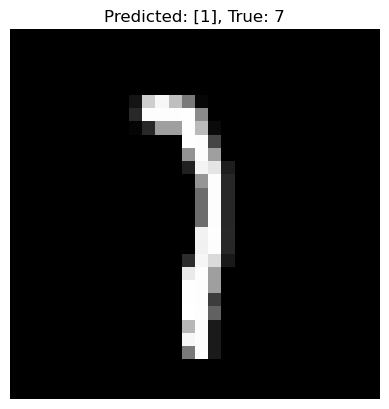

Misclassified index 1281: Predicted [9], True 5


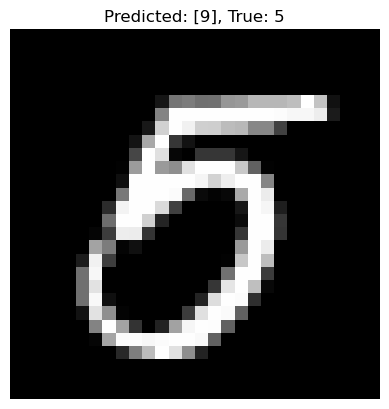

Misclassified index 1283: Predicted [2], True 7


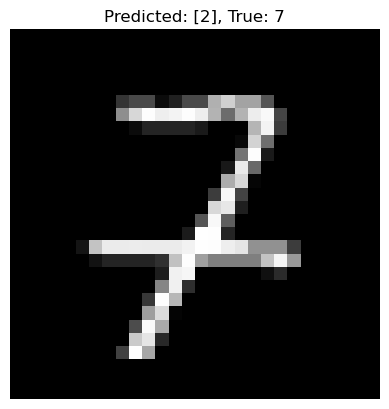

Misclassified index 1289: Predicted [9], True 5


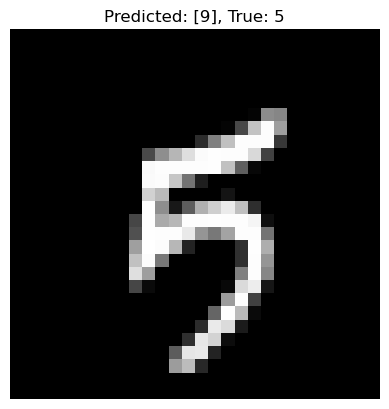

Misclassified index 1299: Predicted [7], True 5


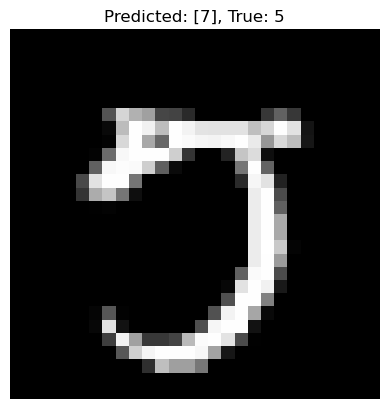

Misclassified index 1319: Predicted [3], True 8


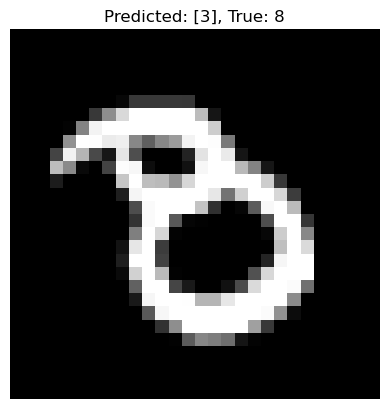

Misclassified index 1325: Predicted [6], True 8


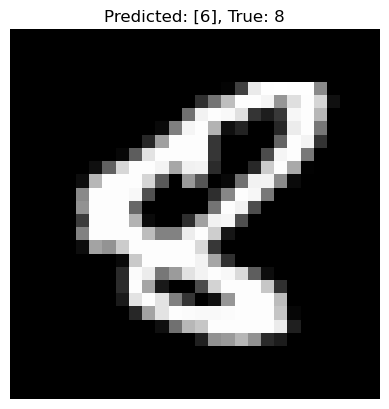

Misclassified index 1326: Predicted [2], True 7


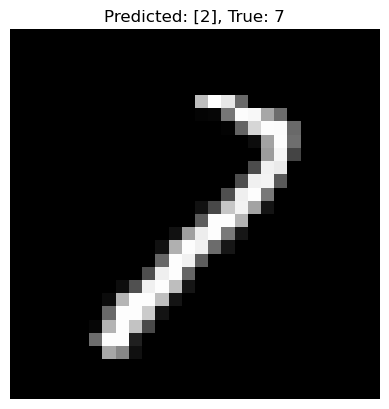

Misclassified index 1328: Predicted [9], True 7


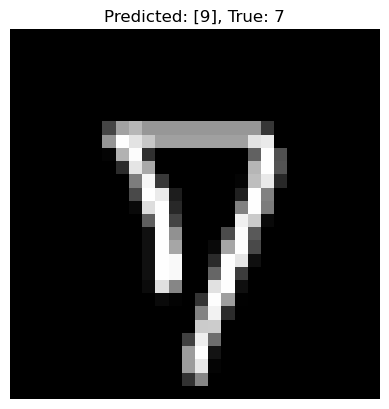

Misclassified index 1364: Predicted [6], True 8


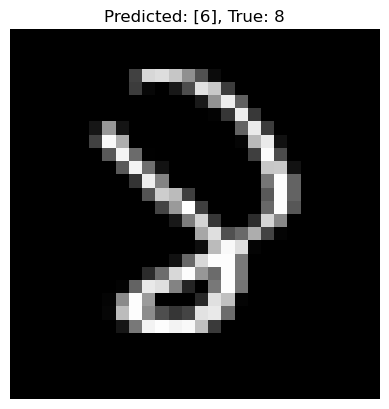

Misclassified index 1378: Predicted [6], True 5


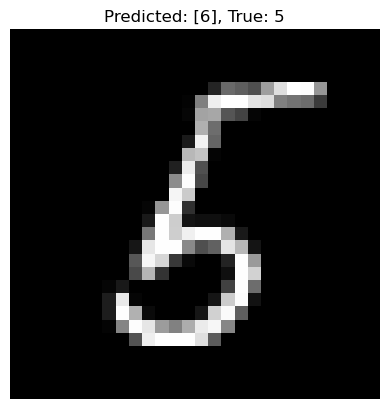

Misclassified index 1393: Predicted [3], True 5


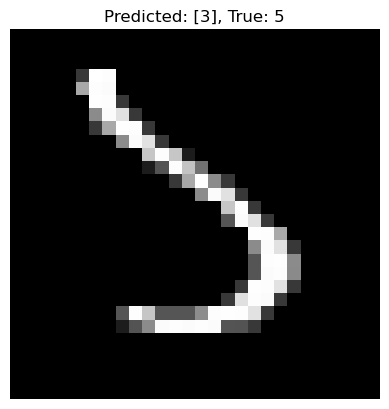

Misclassified index 1425: Predicted [4], True 8


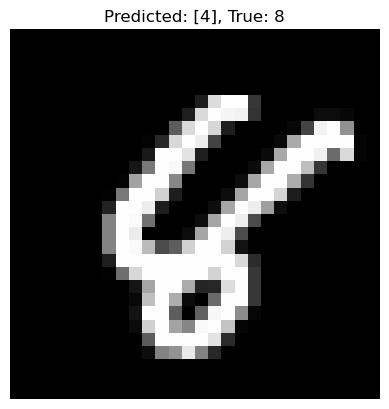

Misclassified index 1467: Predicted [9], True 5


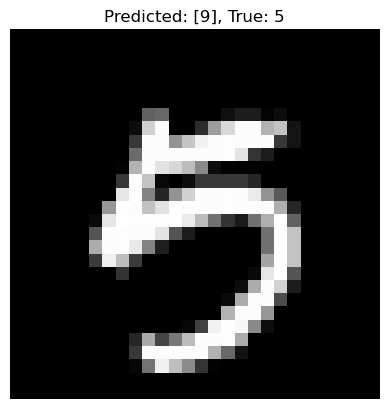

Misclassified index 1496: Predicted [9], True 7


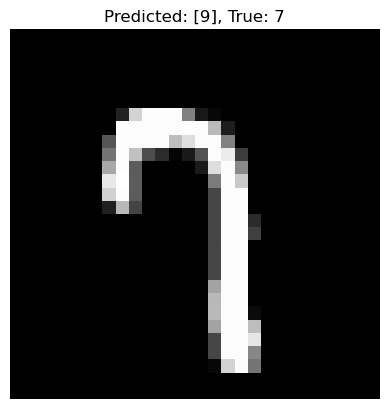

Misclassified index 1500: Predicted [1], True 7


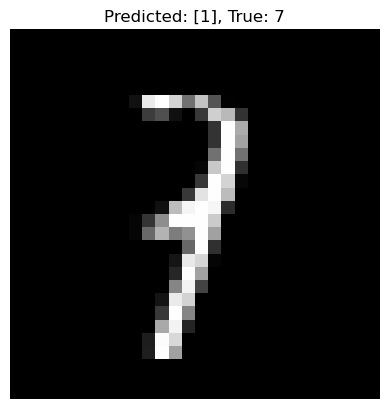

Misclassified index 1520: Predicted [8], True 7


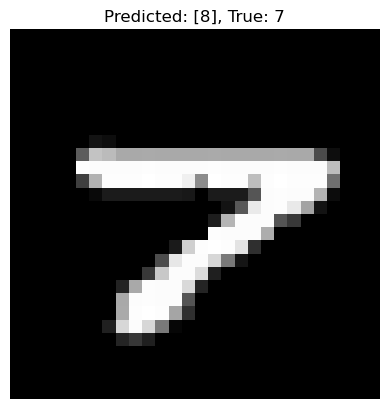

Misclassified index 1522: Predicted [9], True 7


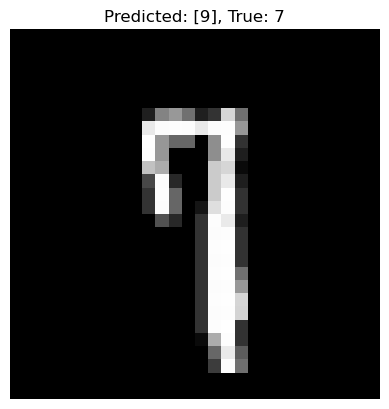

Misclassified index 1527: Predicted [6], True 1


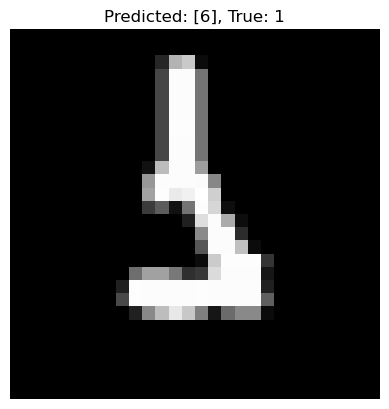

Misclassified index 1530: Predicted [7], True 8


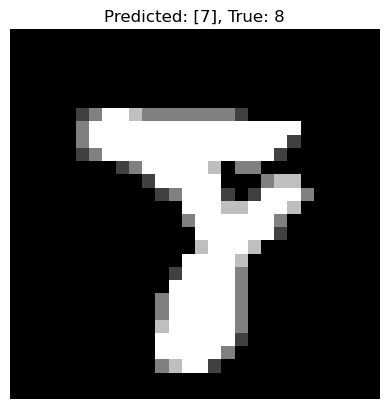

Misclassified index 1549: Predicted [6], True 4


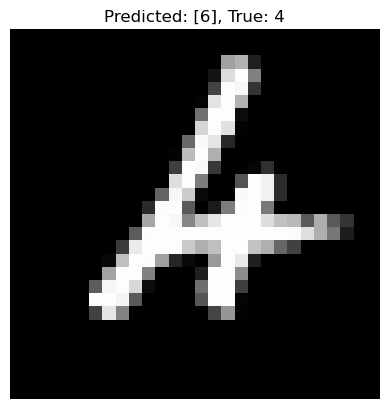

Misclassified index 1551: Predicted [8], True 2


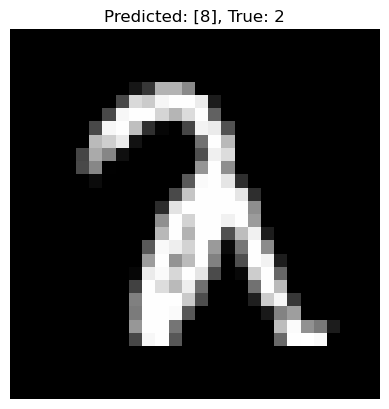

Misclassified index 1553: Predicted [3], True 9


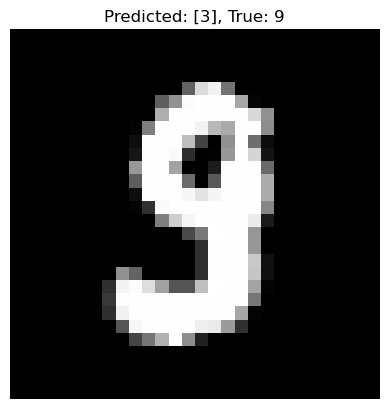

Misclassified index 1584: Predicted [9], True 8


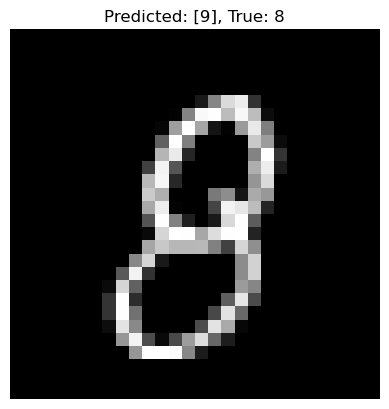

Misclassified index 1609: Predicted [6], True 2


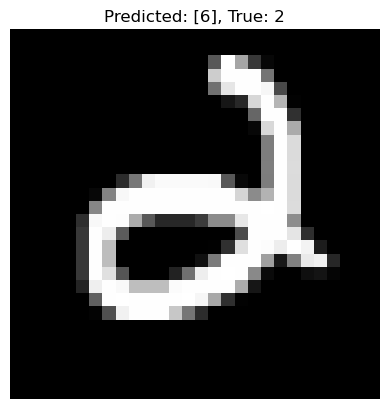

Misclassified index 1621: Predicted [6], True 0


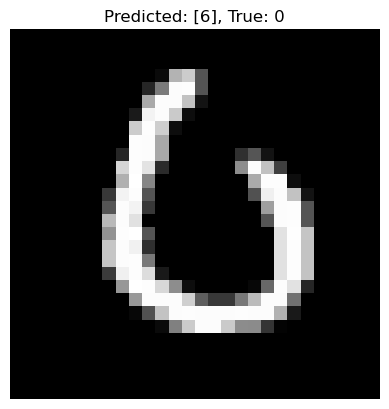

Misclassified index 1641: Predicted [6], True 5


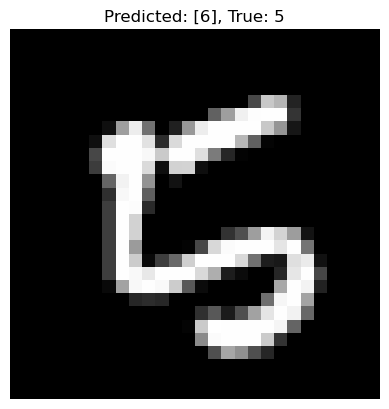

Misclassified index 1671: Predicted [3], True 7


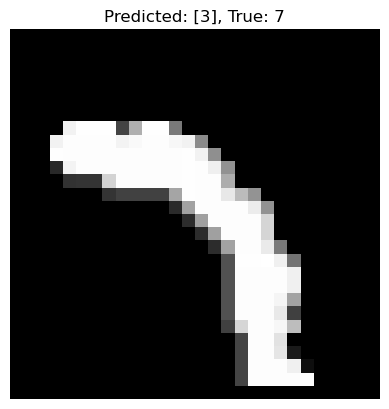

Misclassified index 1678: Predicted [0], True 2


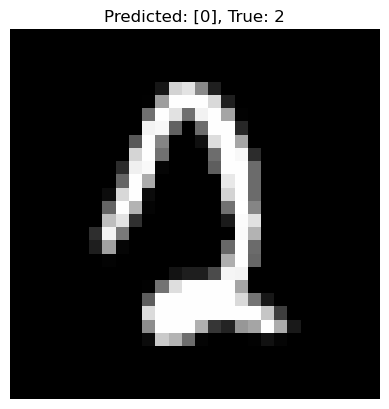

Misclassified index 1681: Predicted [7], True 3


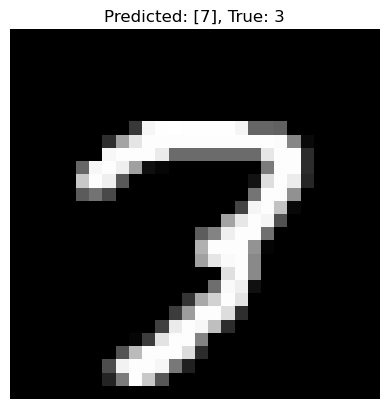

Misclassified index 1709: Predicted [5], True 9


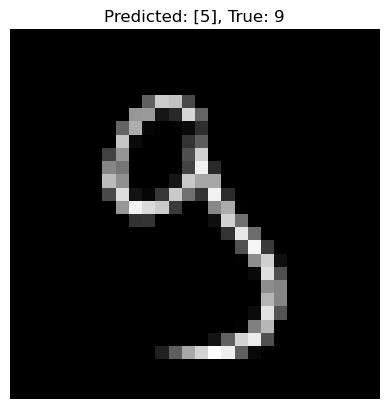

Misclassified index 1717: Predicted [0], True 8


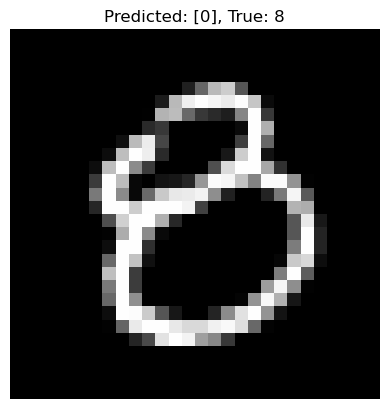

Misclassified index 1737: Predicted [8], True 5


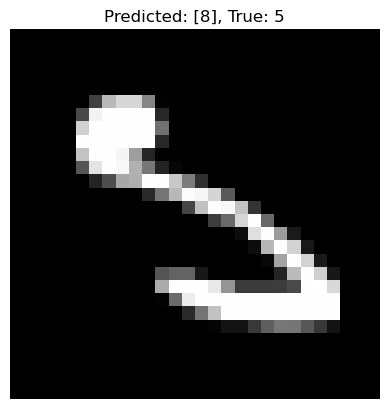

Misclassified index 1751: Predicted [2], True 4


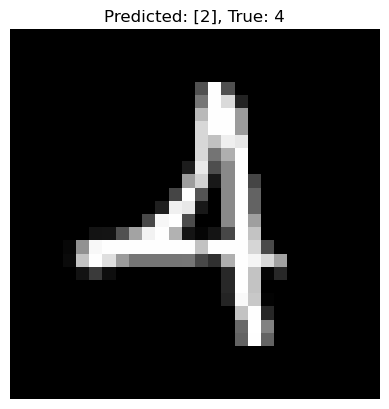

Misclassified index 1754: Predicted [3], True 7


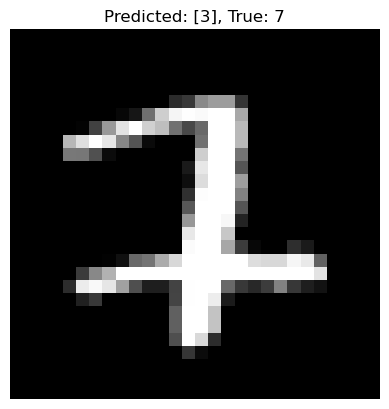

Misclassified index 1781: Predicted [4], True 9


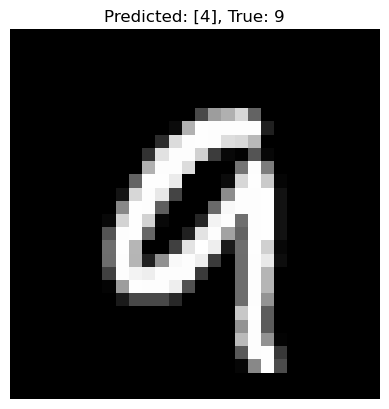

Misclassified index 1790: Predicted [8], True 2


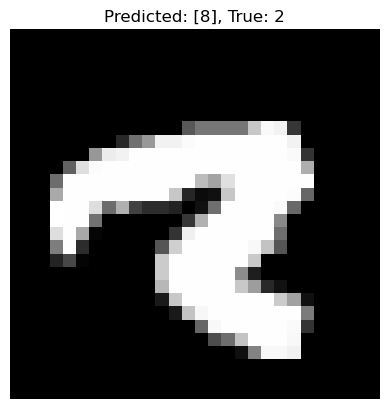

Misclassified index 1800: Predicted [2], True 6


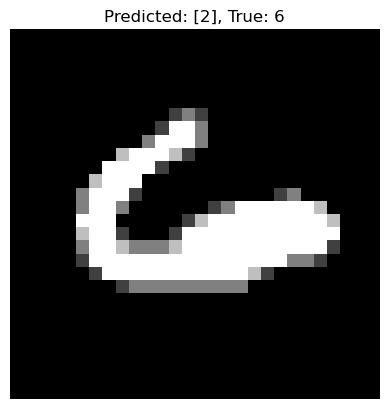

Misclassified index 1883: Predicted [9], True 7


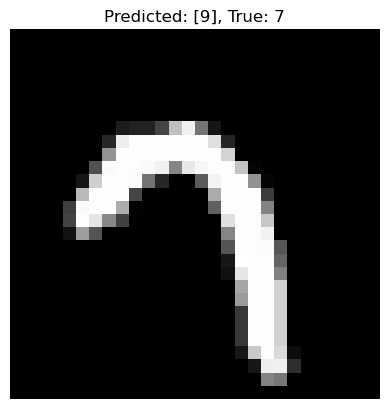

Misclassified index 1901: Predicted [4], True 9


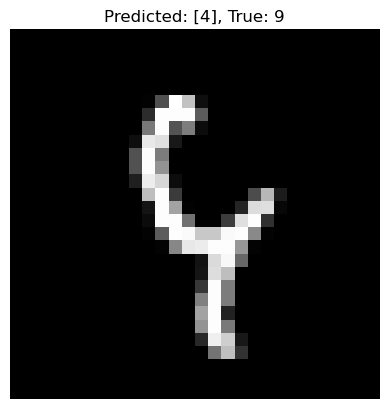

Misclassified index 1940: Predicted [0], True 5


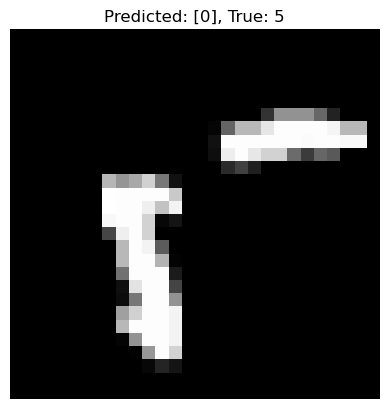

Misclassified index 1941: Predicted [9], True 7


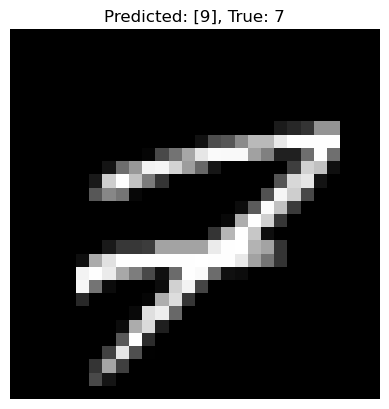

Misclassified index 1984: Predicted [0], True 2


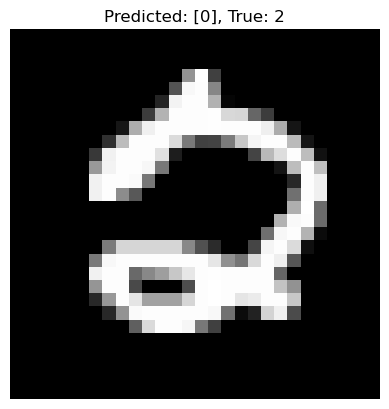

Misclassified index 2016: Predicted [2], True 7


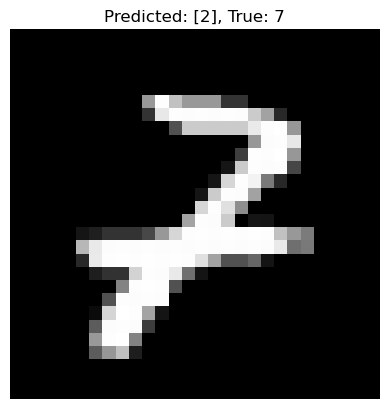

Misclassified index 2018: Predicted [7], True 1


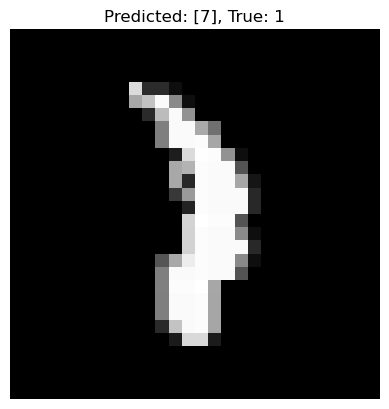

Misclassified index 2024: Predicted [9], True 7


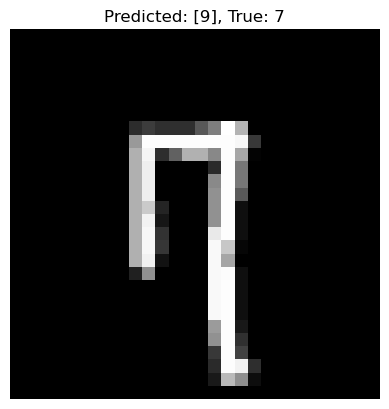

Misclassified index 2033: Predicted [4], True 0


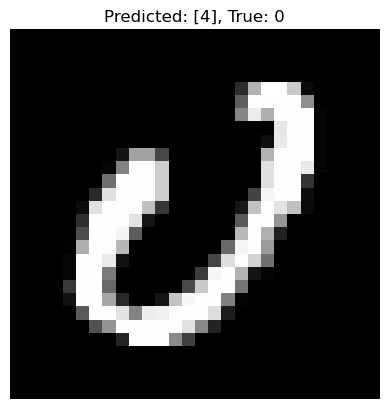

Misclassified index 2035: Predicted [3], True 5


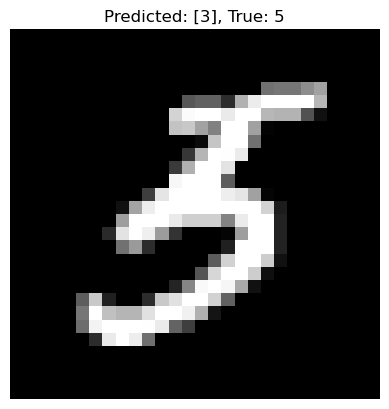

Misclassified index 2040: Predicted [4], True 5


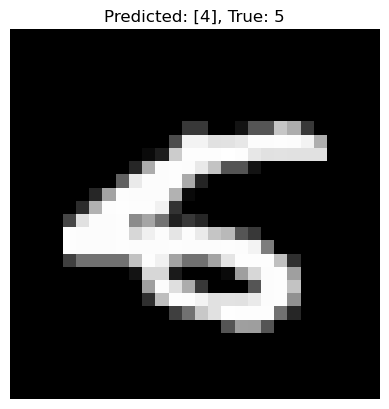

Misclassified index 2044: Predicted [7], True 2


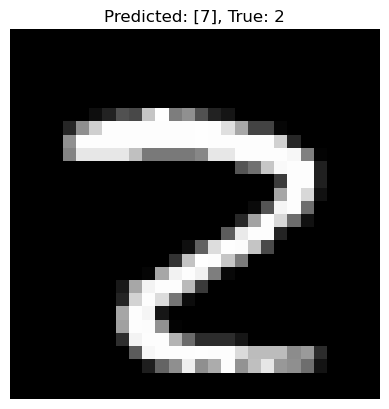

Misclassified index 2053: Predicted [9], True 4


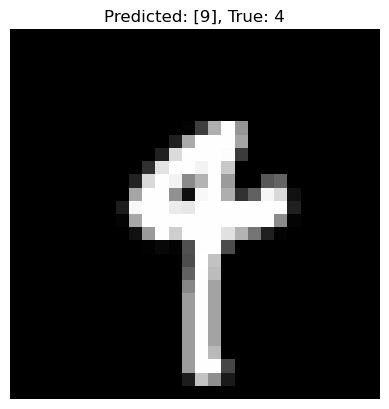

Misclassified index 2098: Predicted [0], True 2


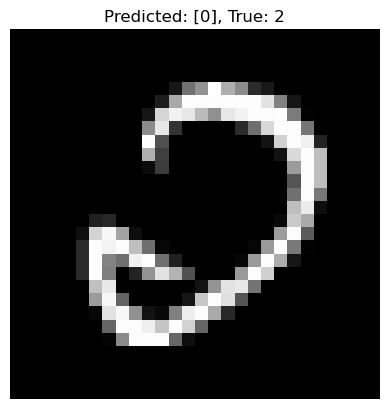

Misclassified index 2109: Predicted [9], True 3


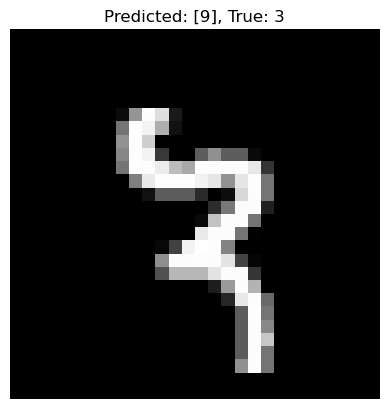

Misclassified index 2118: Predicted [0], True 6


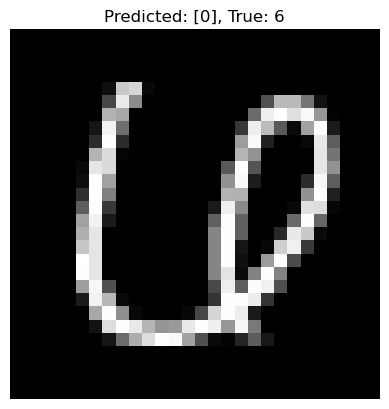

Misclassified index 2135: Predicted [1], True 6


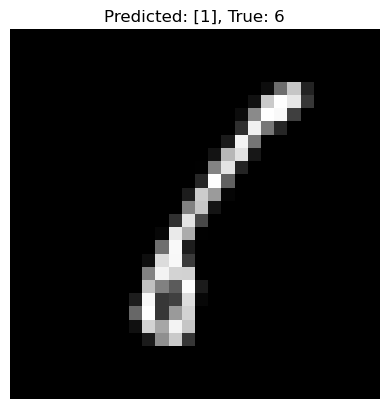

Misclassified index 2179: Predicted [3], True 8


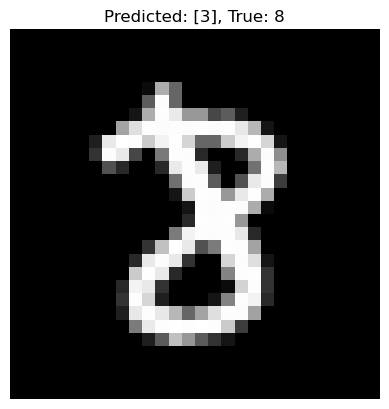

Misclassified index 2182: Predicted [2], True 1


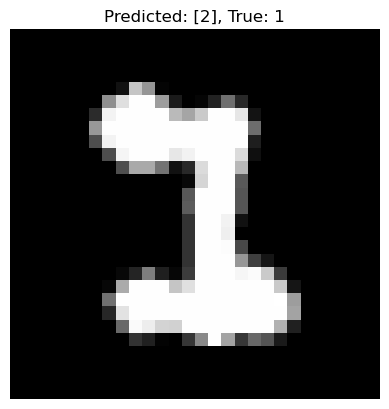

Misclassified index 2186: Predicted [3], True 2


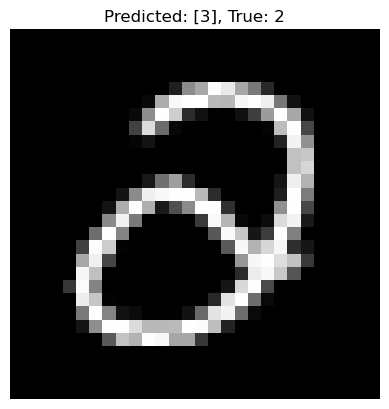

Misclassified index 2224: Predicted [6], True 5


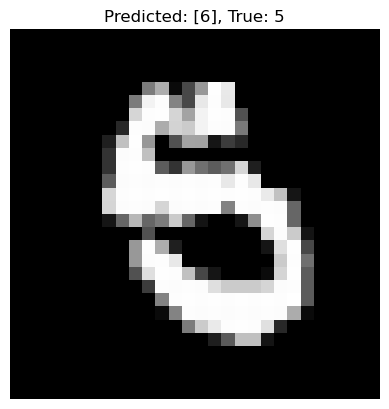

Misclassified index 2266: Predicted [6], True 1


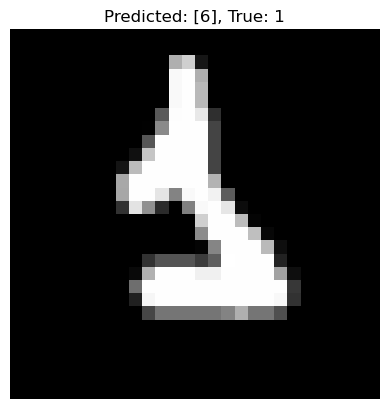

Misclassified index 2272: Predicted [0], True 8


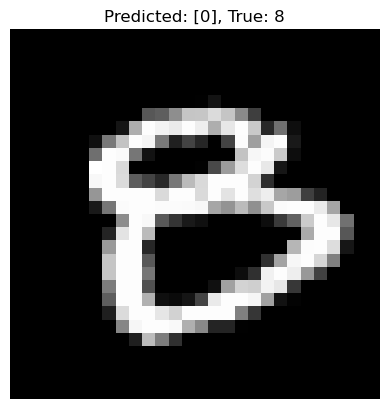

Misclassified index 2293: Predicted [0], True 9


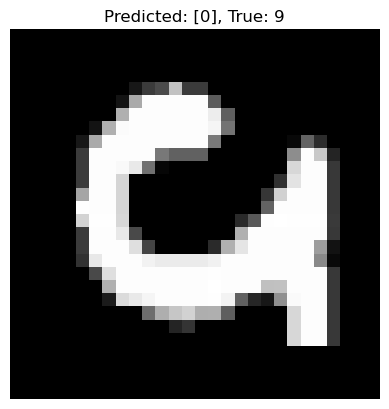

Misclassified index 2299: Predicted [7], True 2


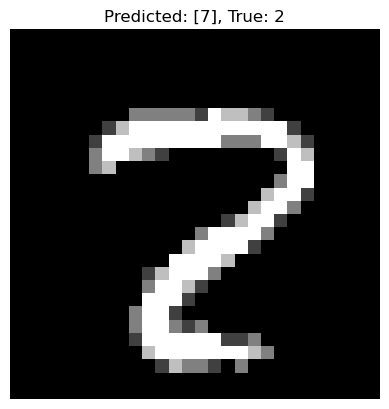

Misclassified index 2369: Predicted [9], True 5


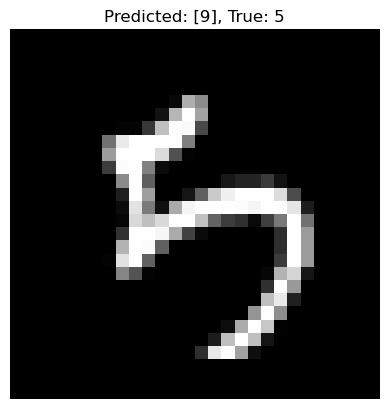

Misclassified index 2387: Predicted [1], True 9


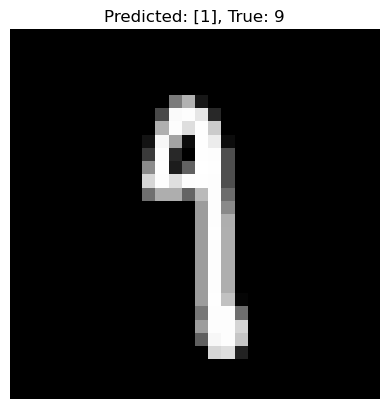

Misclassified index 2394: Predicted [9], True 4


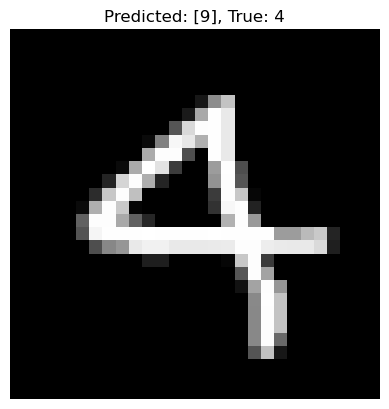

Misclassified index 2395: Predicted [3], True 8


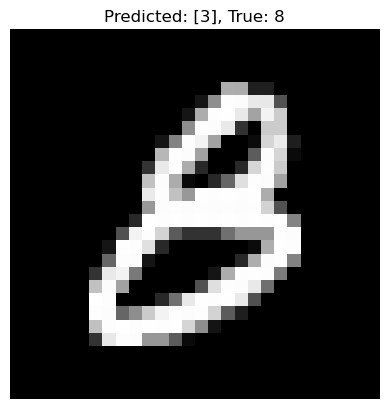

Misclassified index 2406: Predicted [1], True 9


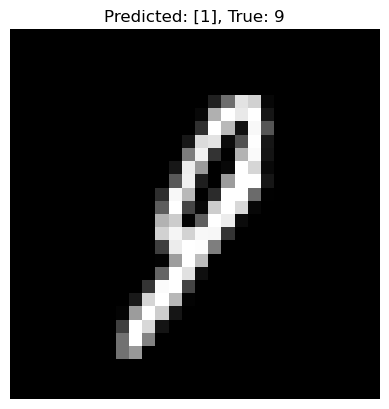

Misclassified index 2408: Predicted [9], True 3


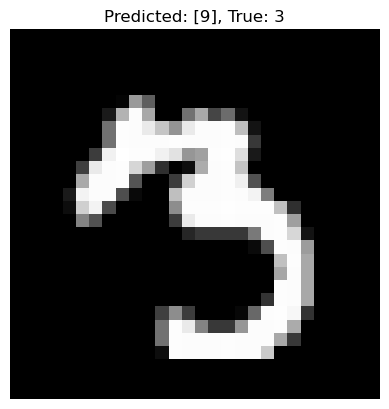

Misclassified index 2414: Predicted [4], True 9


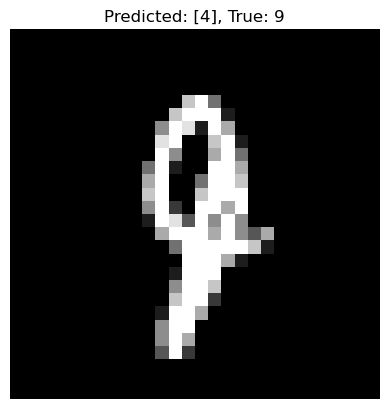

Misclassified index 2422: Predicted [4], True 6


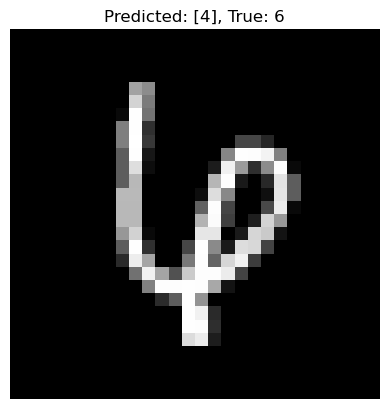

Misclassified index 2426: Predicted [4], True 9


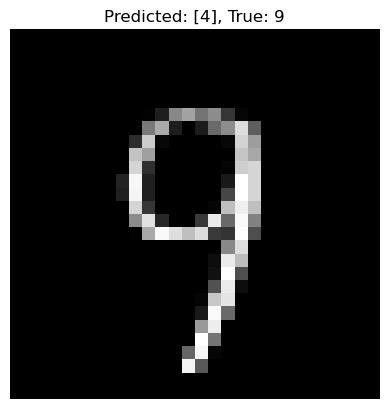

Misclassified index 2433: Predicted [1], True 2


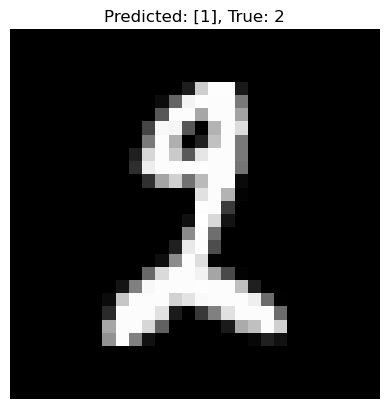

Misclassified index 2462: Predicted [0], True 2


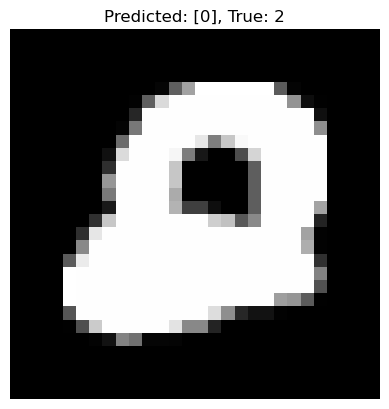

Misclassified index 2488: Predicted [4], True 2


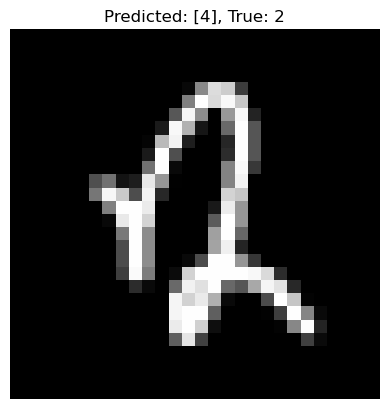

Misclassified index 2560: Predicted [1], True 3


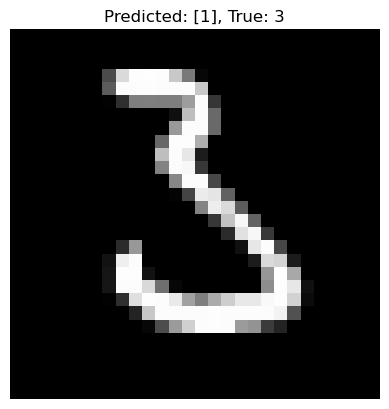

Misclassified index 2607: Predicted [1], True 7


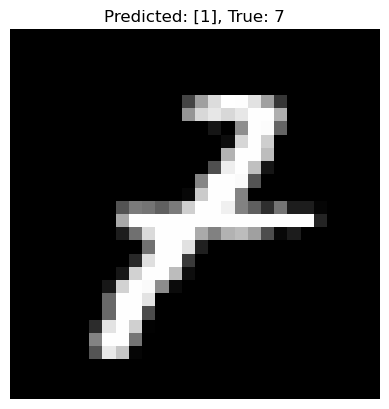

Misclassified index 2654: Predicted [1], True 6


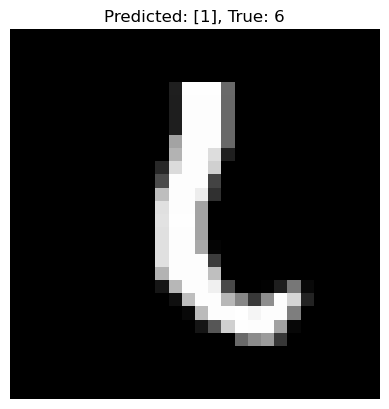

Misclassified index 2658: Predicted [6], True 4


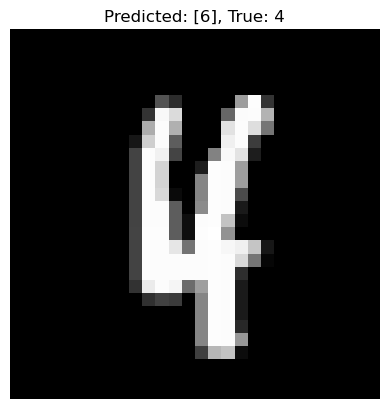

Misclassified index 2713: Predicted [8], True 0


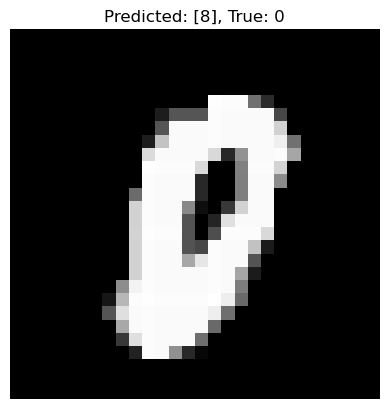

Misclassified index 2720: Predicted [4], True 9


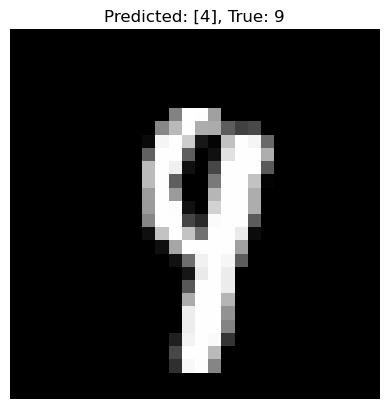

Misclassified index 2721: Predicted [8], True 6


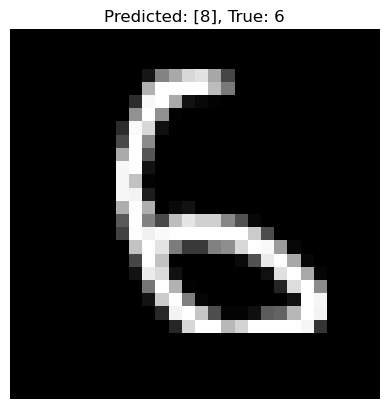

Misclassified index 2810: Predicted [3], True 5


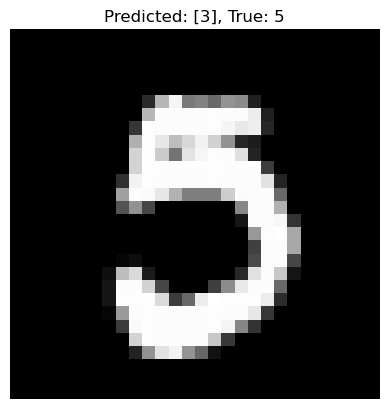

Misclassified index 2863: Predicted [4], True 9


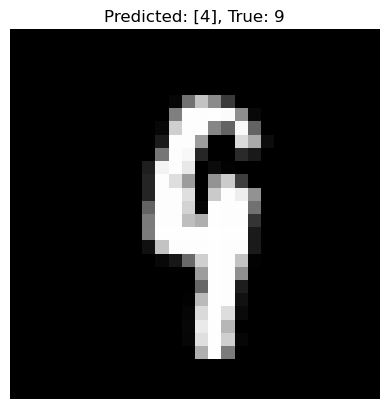

Misclassified index 2877: Predicted [9], True 4


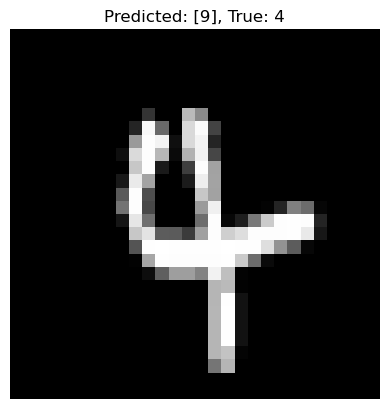

Misclassified index 2896: Predicted [0], True 8


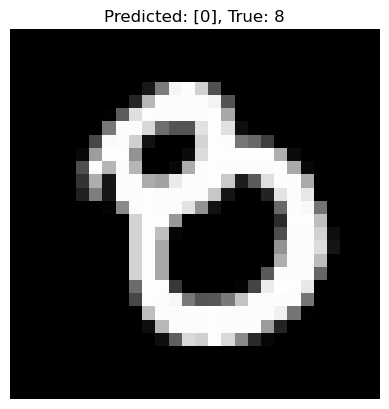

Misclassified index 2921: Predicted [2], True 3


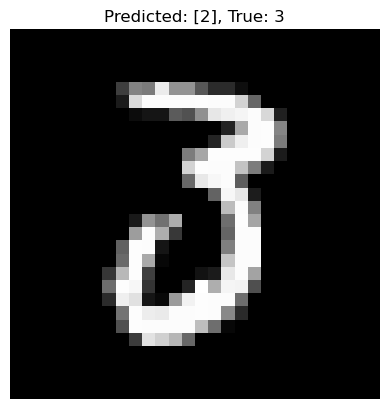

Misclassified index 2927: Predicted [7], True 3


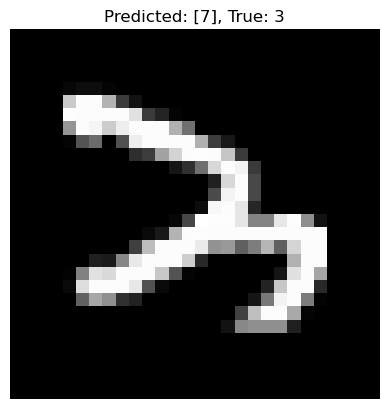

Misclassified index 2939: Predicted [5], True 9


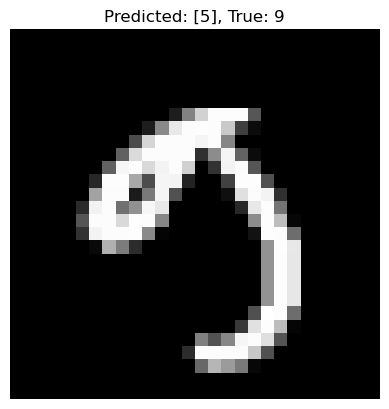

Misclassified index 2953: Predicted [8], True 3


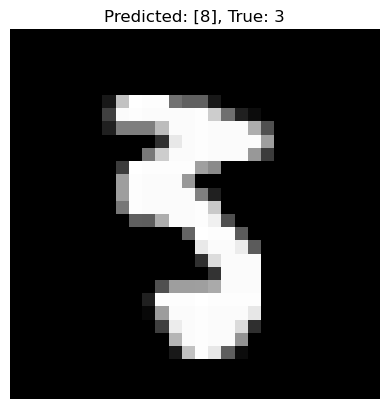

Misclassified index 2970: Predicted [3], True 5


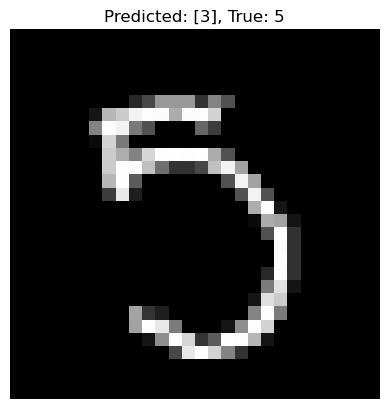

Misclassified index 2995: Predicted [8], True 6


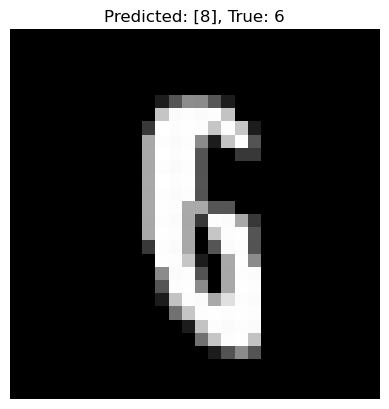

Misclassified index 3001: Predicted [8], True 9


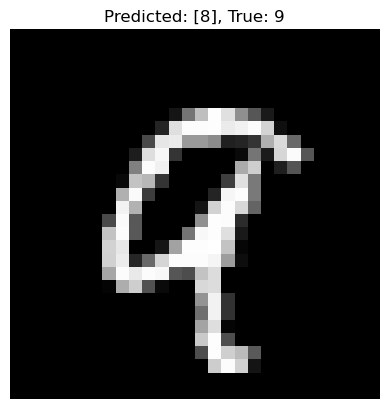

Misclassified index 3005: Predicted [1], True 9


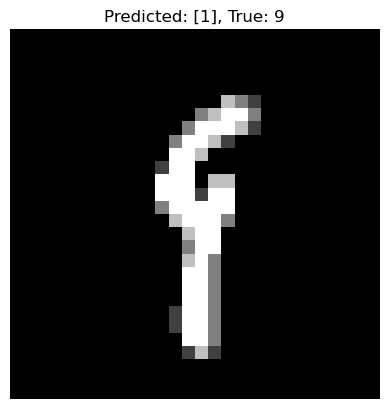

Misclassified index 3030: Predicted [8], True 6


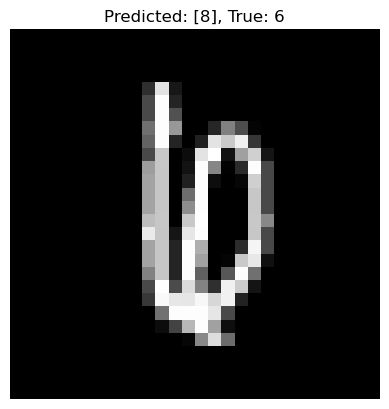

Misclassified index 3060: Predicted [7], True 9


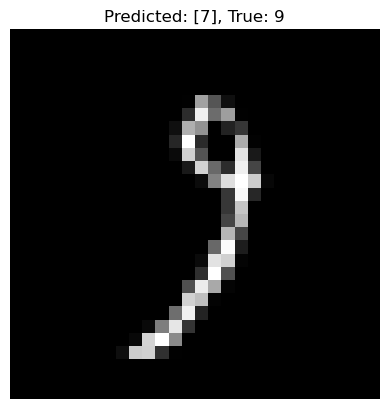

Misclassified index 3073: Predicted [2], True 1


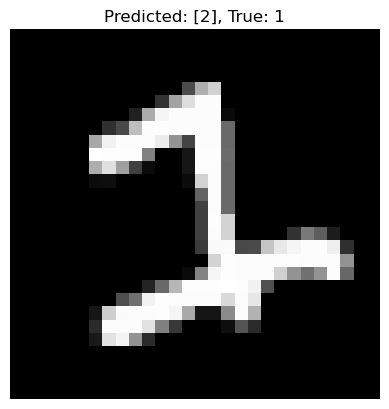

Misclassified index 3102: Predicted [3], True 5


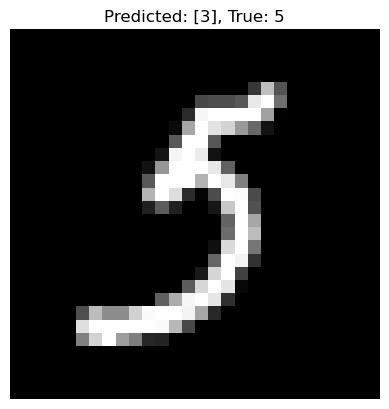

Misclassified index 3114: Predicted [6], True 4


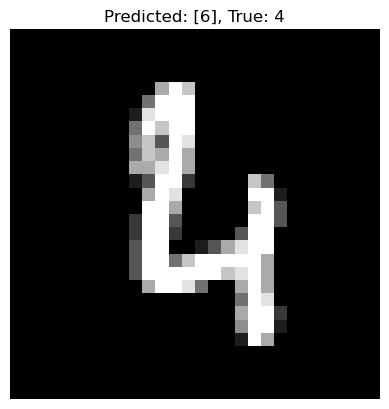

Misclassified index 3115: Predicted [4], True 5


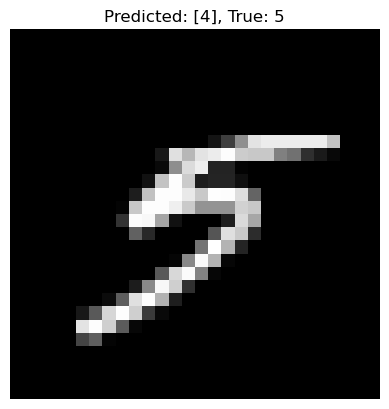

Misclassified index 3117: Predicted [9], True 5


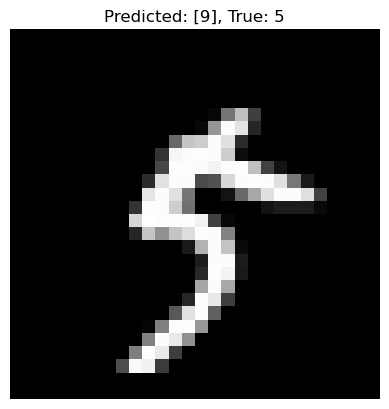

Misclassified index 3130: Predicted [0], True 6


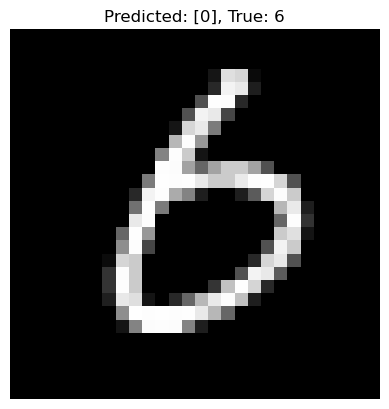

Misclassified index 3145: Predicted [9], True 5


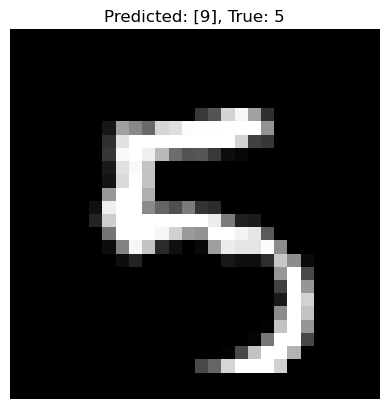

Misclassified index 3206: Predicted [3], True 8


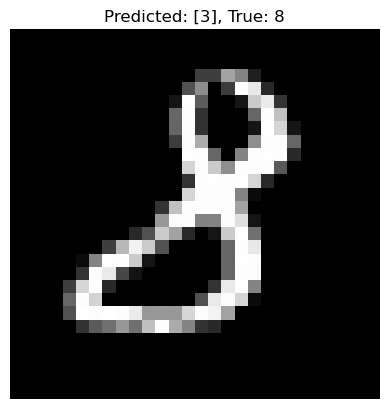

Misclassified index 3263: Predicted [7], True 8


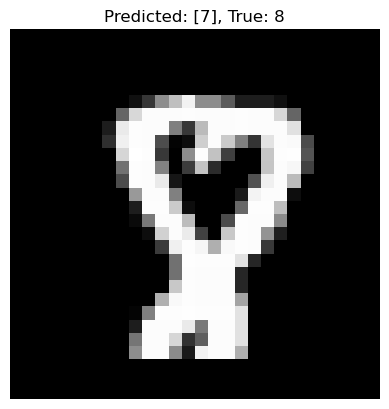

Misclassified index 3333: Predicted [9], True 7


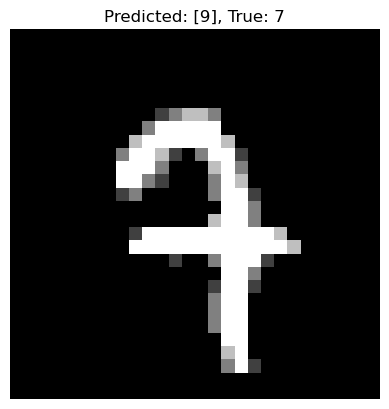

Misclassified index 3369: Predicted [1], True 9


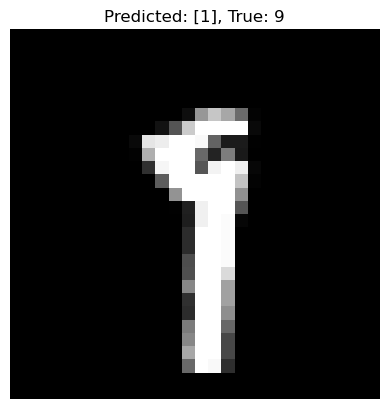

Misclassified index 3422: Predicted [0], True 6


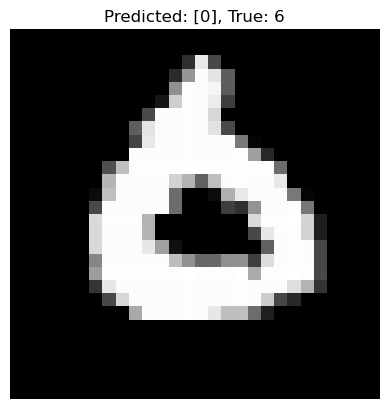

Misclassified index 3490: Predicted [9], True 4


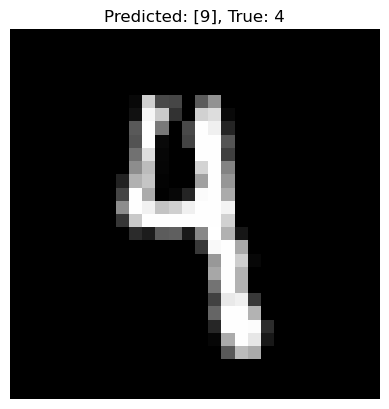

Misclassified index 3503: Predicted [1], True 9


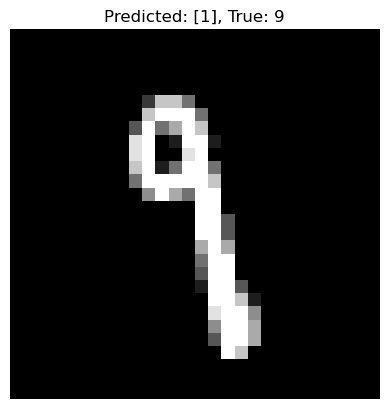

Misclassified index 3520: Predicted [4], True 6


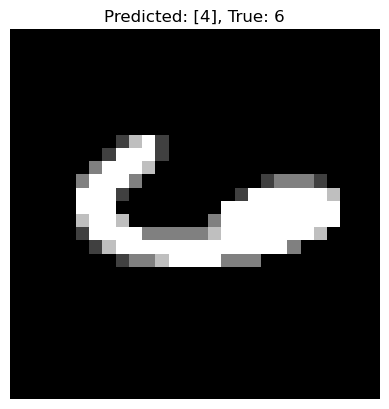

Misclassified index 3549: Predicted [2], True 3


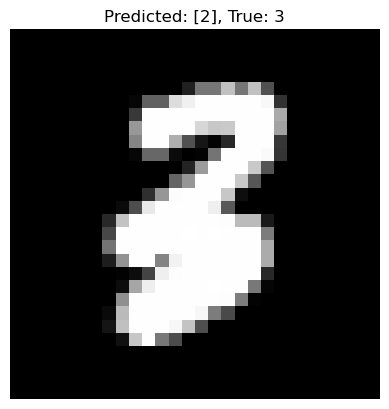

Misclassified index 3552: Predicted [0], True 5


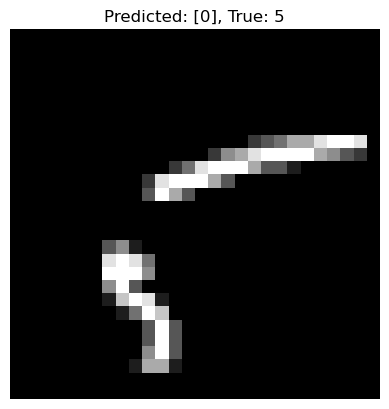

Misclassified index 3558: Predicted [0], True 5


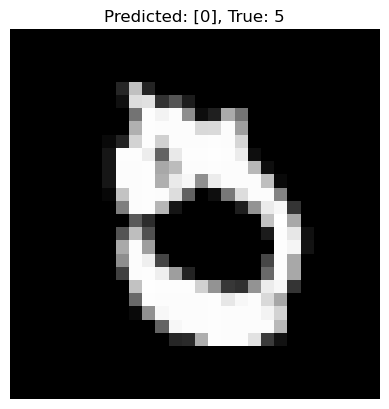

Misclassified index 3559: Predicted [5], True 8


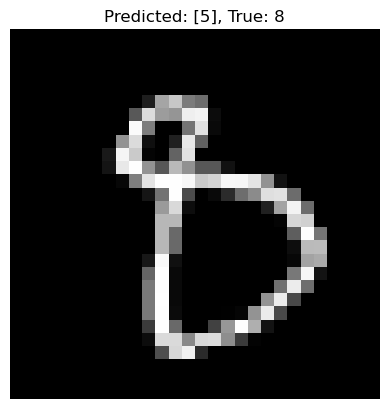

Misclassified index 3574: Predicted [5], True 0


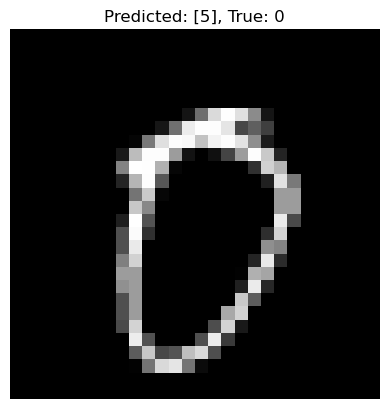

Misclassified index 3575: Predicted [8], True 7


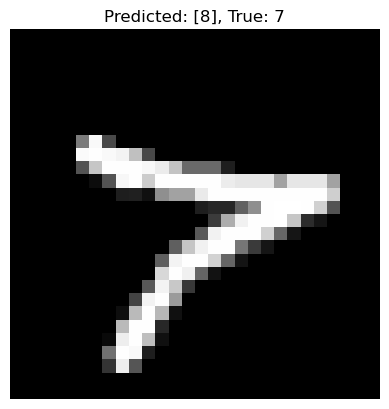

Misclassified index 3710: Predicted [2], True 0


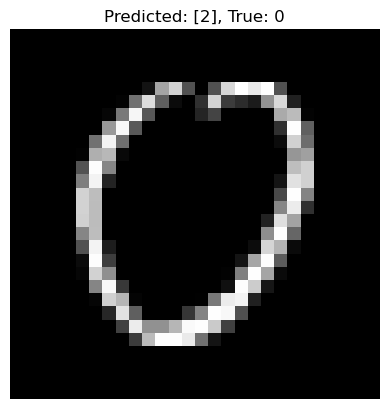

Misclassified index 3776: Predicted [8], True 5


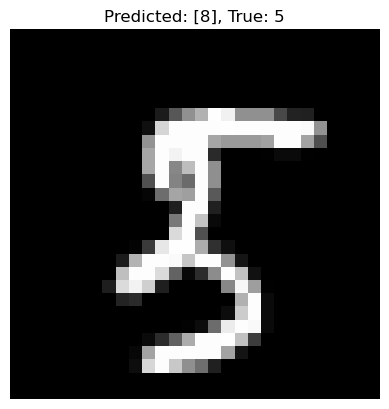

Misclassified index 3780: Predicted [6], True 4


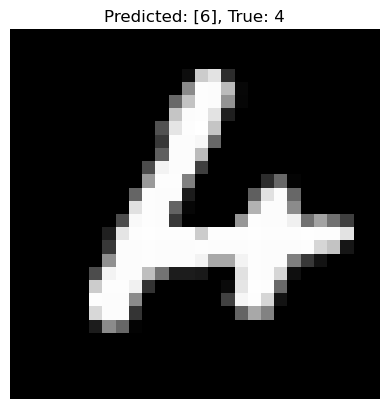

Misclassified index 3838: Predicted [1], True 7


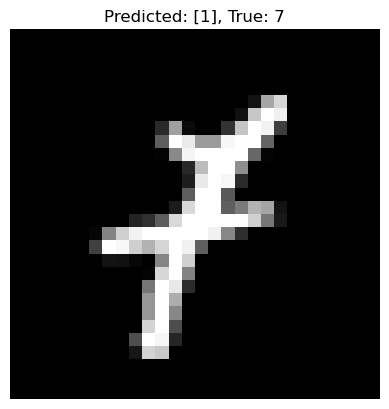

Misclassified index 3846: Predicted [7], True 6


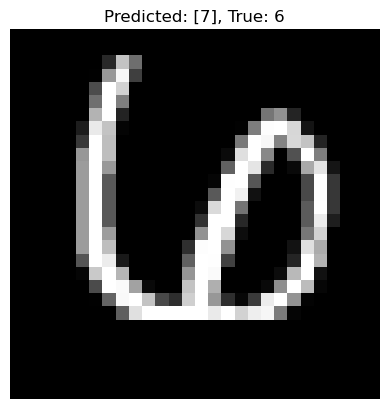

Misclassified index 3853: Predicted [2], True 6


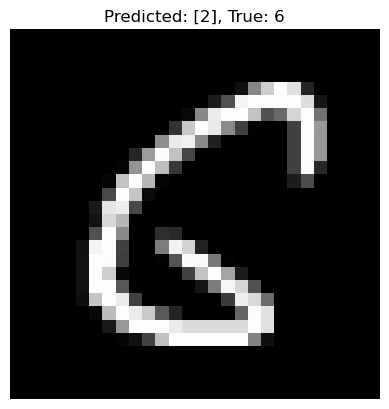

Misclassified index 3855: Predicted [0], True 5


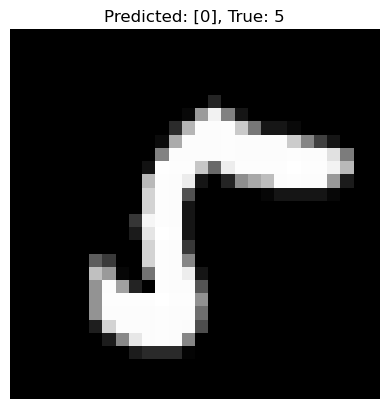

Misclassified index 3869: Predicted [4], True 9


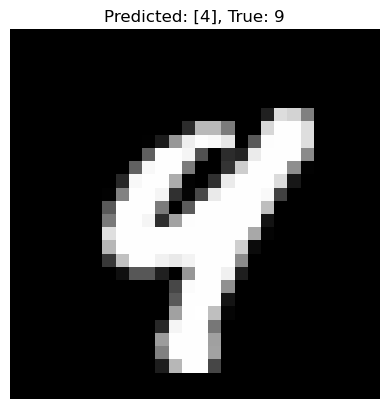

Misclassified index 3893: Predicted [6], True 5


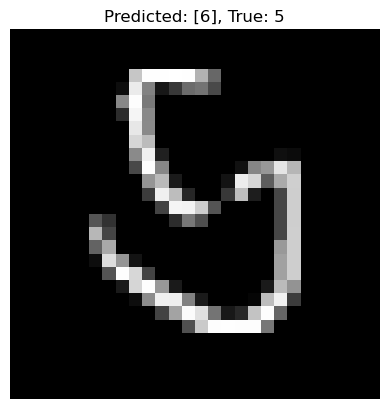

Misclassified index 3902: Predicted [3], True 5


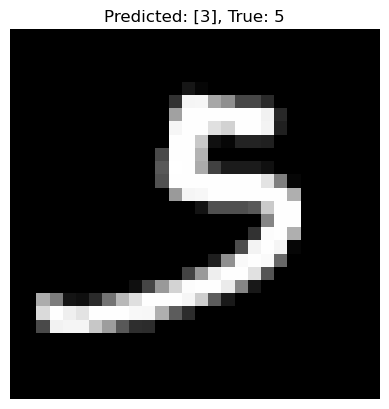

Misclassified index 3906: Predicted [3], True 1


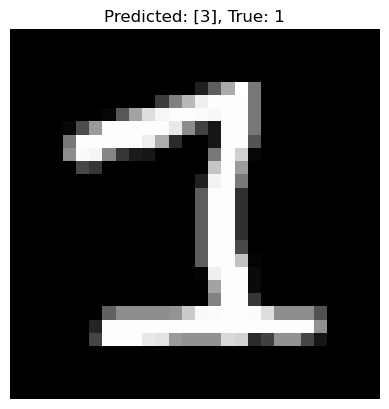

Misclassified index 3941: Predicted [2], True 4


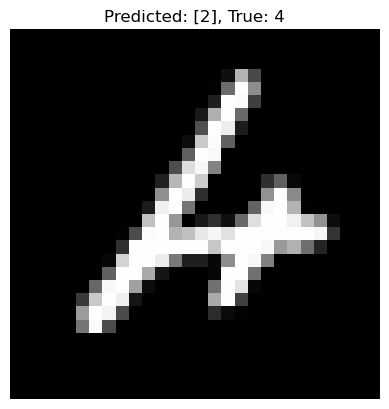

Misclassified index 3976: Predicted [1], True 7


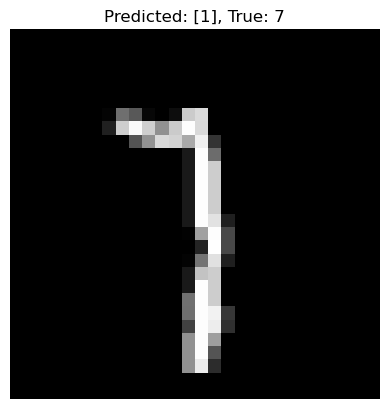

Misclassified index 3985: Predicted [4], True 9


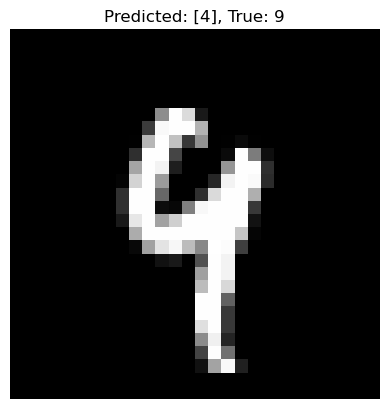

Misclassified index 3988: Predicted [9], True 8


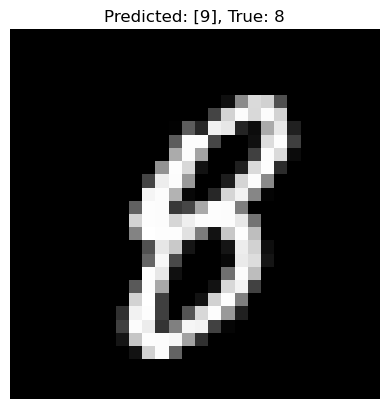

Misclassified index 4065: Predicted [9], True 0


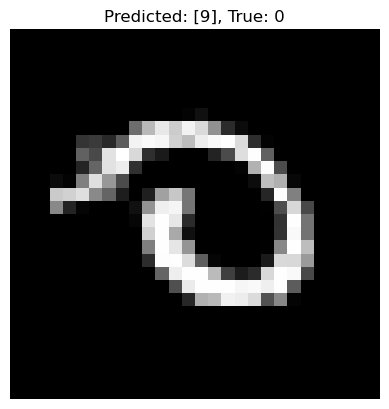

Misclassified index 4072: Predicted [3], True 5


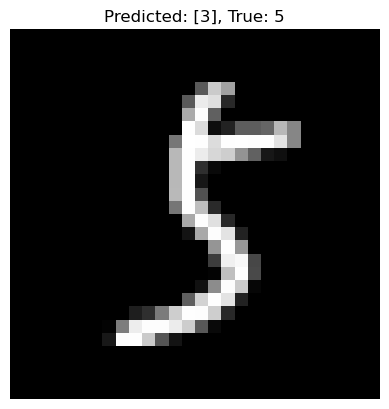

Misclassified index 4075: Predicted [0], True 8


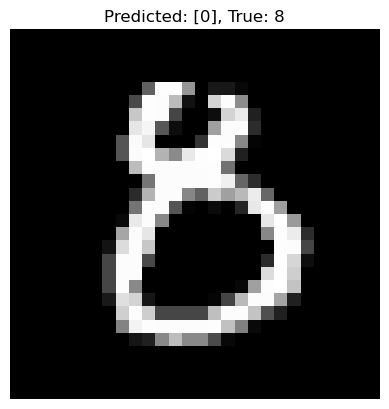

Misclassified index 4078: Predicted [8], True 9


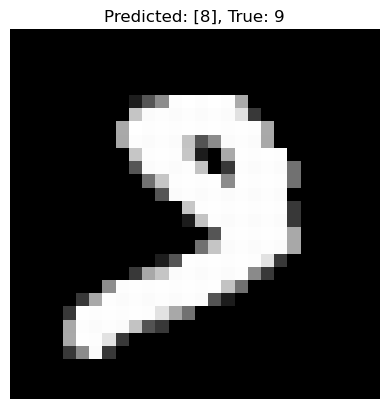

Misclassified index 4093: Predicted [4], True 9


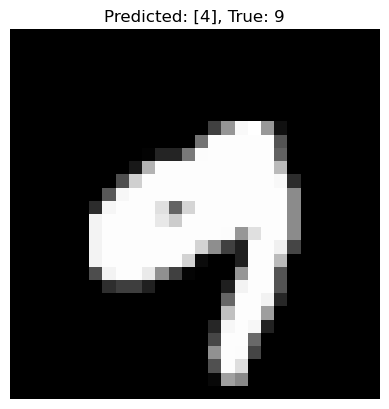

Misclassified index 4152: Predicted [1], True 5


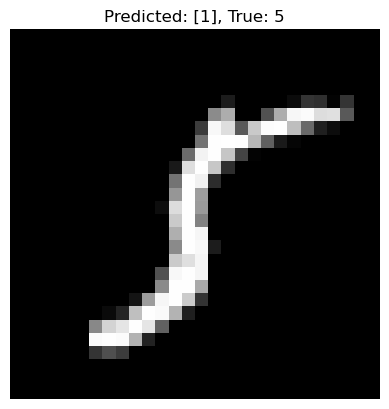

Misclassified index 4176: Predicted [7], True 2


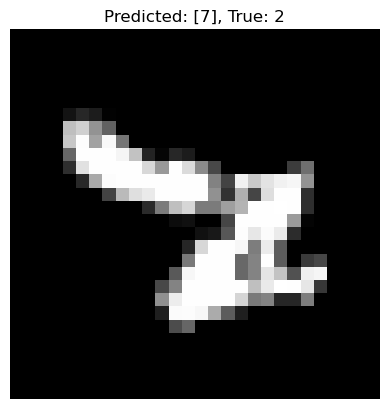

Misclassified index 4199: Predicted [9], True 7


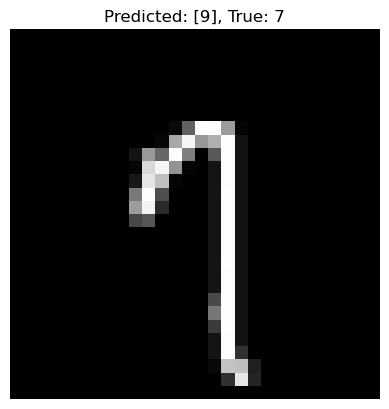

Misclassified index 4224: Predicted [7], True 9


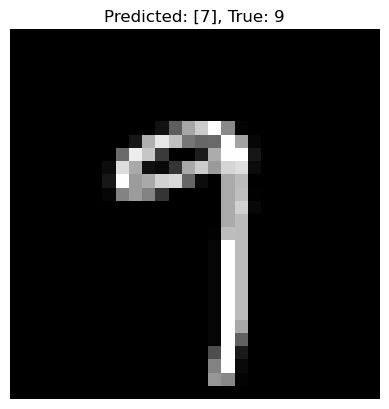

Misclassified index 4248: Predicted [1], True 2


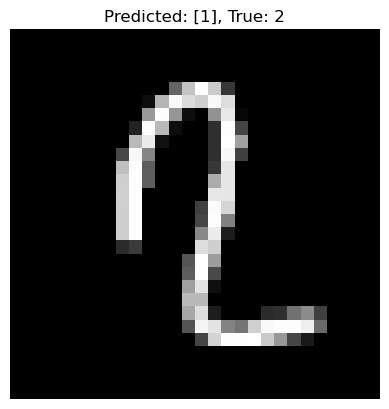

Misclassified index 4255: Predicted [3], True 5


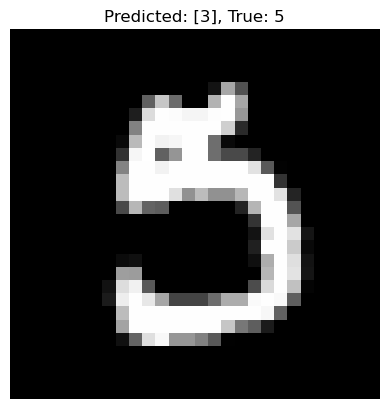

Misclassified index 4256: Predicted [2], True 3


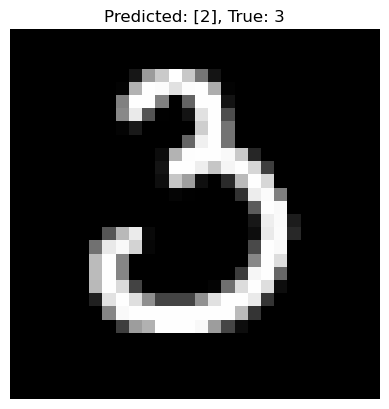

Misclassified index 4271: Predicted [3], True 5


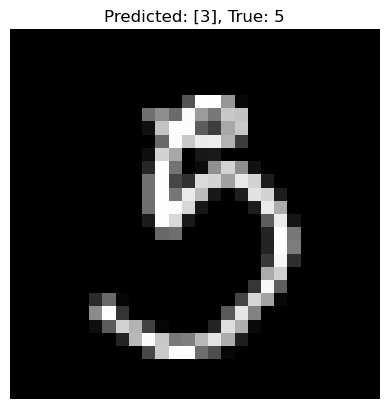

Misclassified index 4289: Predicted [8], True 2


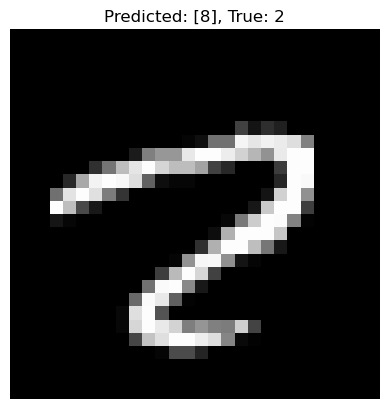

Misclassified index 4355: Predicted [9], True 5


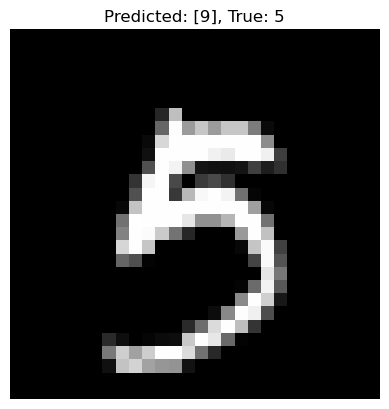

Misclassified index 4360: Predicted [3], True 5


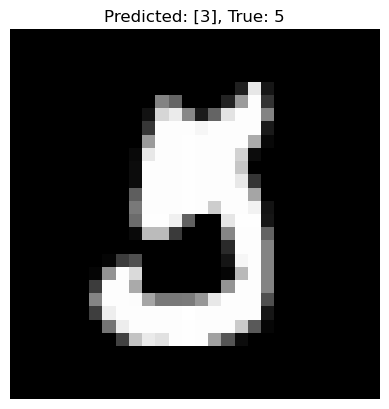

Misclassified index 4369: Predicted [4], True 9


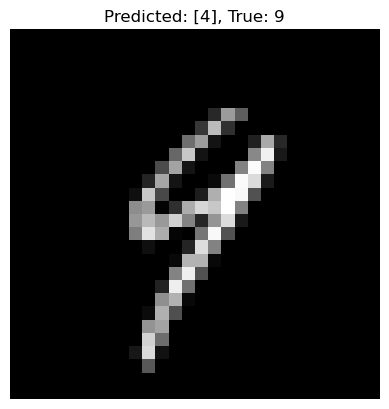

Misclassified index 4425: Predicted [4], True 9


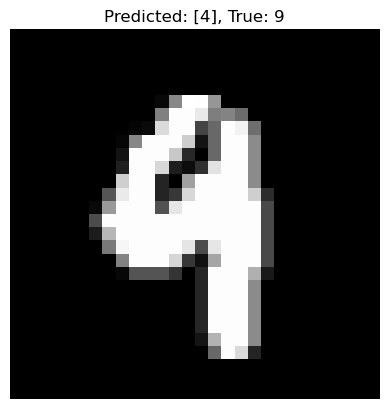

Misclassified index 4437: Predicted [2], True 3


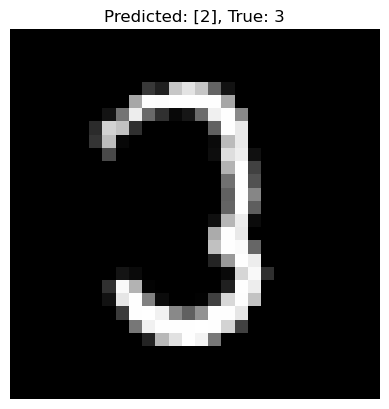

Misclassified index 4443: Predicted [2], True 3


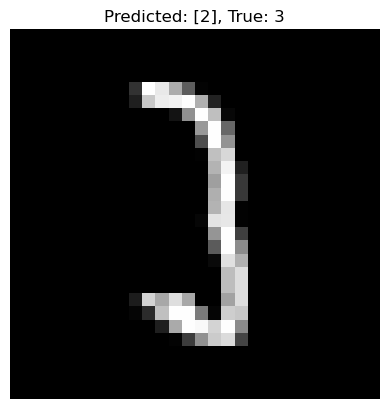

Misclassified index 4451: Predicted [8], True 2


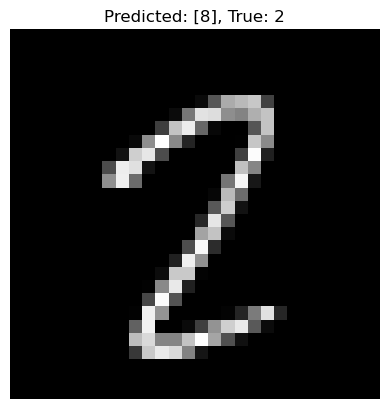

Misclassified index 4497: Predicted [7], True 8


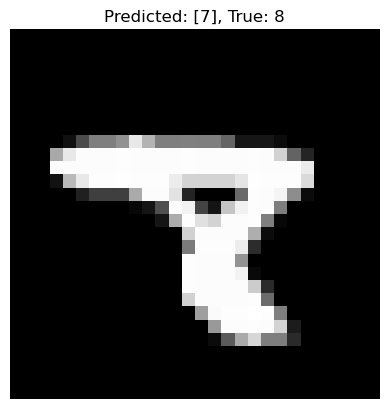

Misclassified index 4498: Predicted [3], True 7


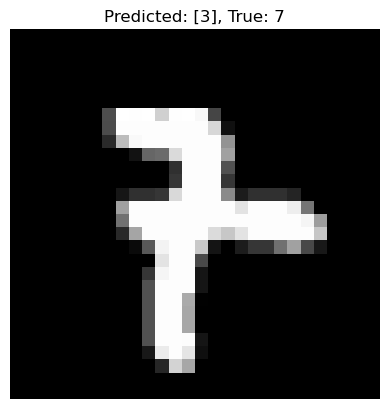

Misclassified index 4500: Predicted [1], True 9


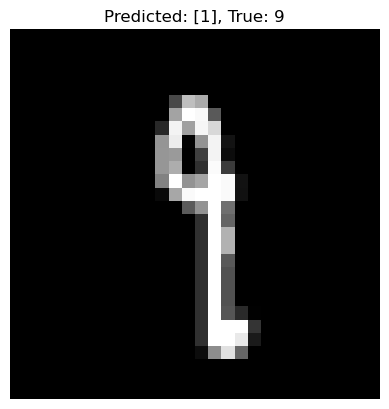

Misclassified index 4534: Predicted [8], True 9


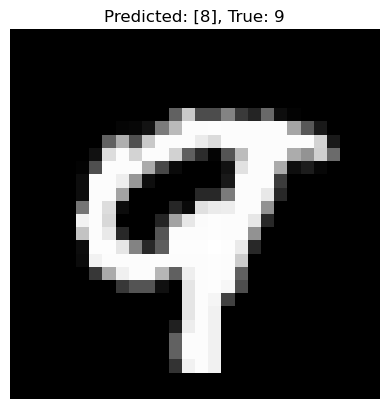

Misclassified index 4536: Predicted [5], True 6


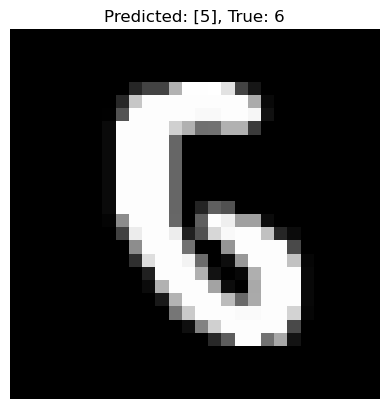

Misclassified index 4548: Predicted [6], True 5


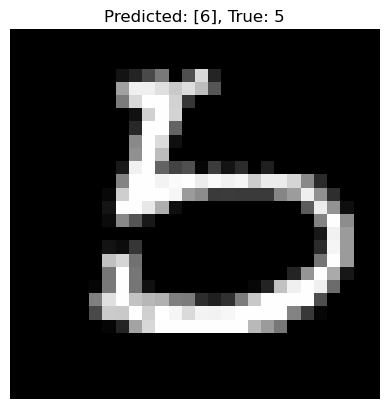

Misclassified index 4578: Predicted [9], True 7


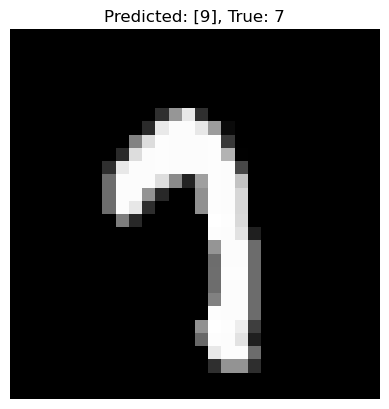

Misclassified index 4601: Predicted [4], True 8


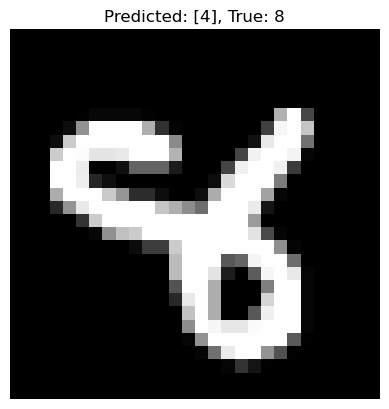

Misclassified index 4656: Predicted [7], True 2


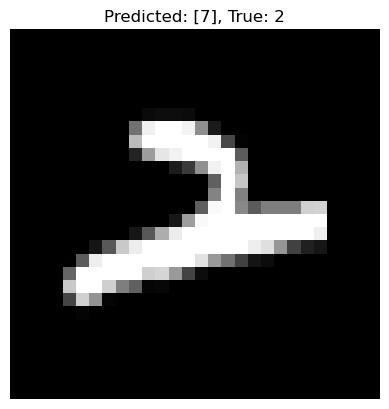

Misclassified index 4731: Predicted [7], True 8


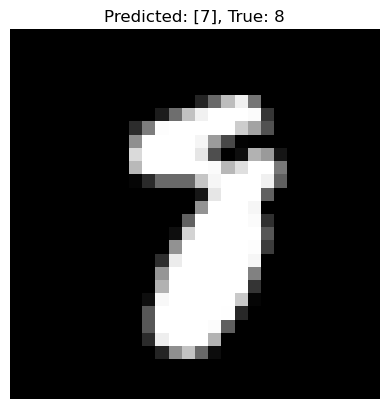

Misclassified index 4807: Predicted [3], True 8


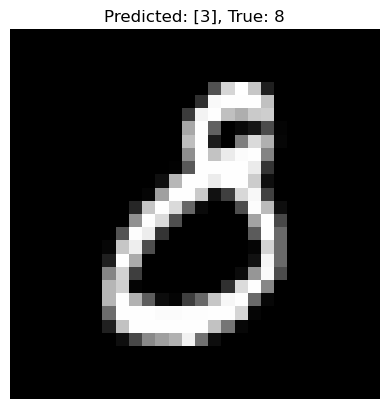

Misclassified index 4814: Predicted [4], True 6


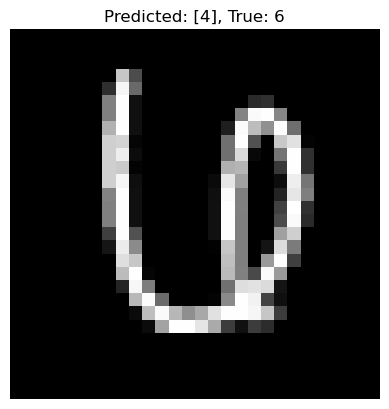

Misclassified index 4823: Predicted [4], True 9


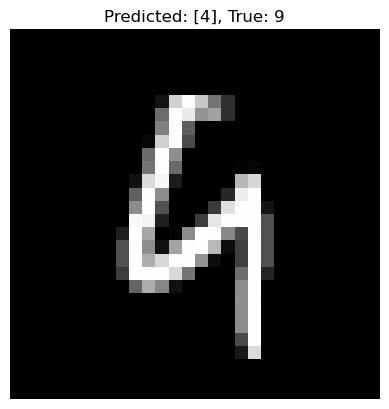

Misclassified index 4874: Predicted [0], True 9


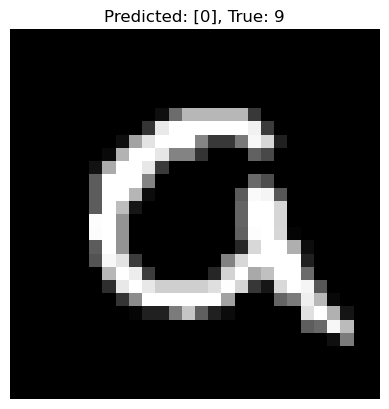

Misclassified index 4876: Predicted [4], True 2


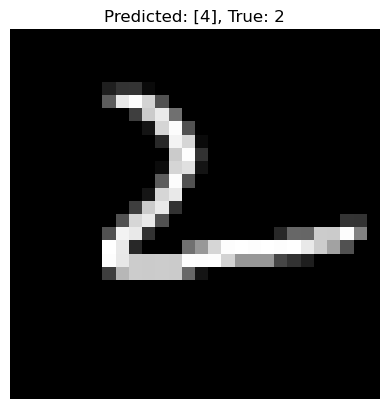

Misclassified index 4880: Predicted [8], True 0


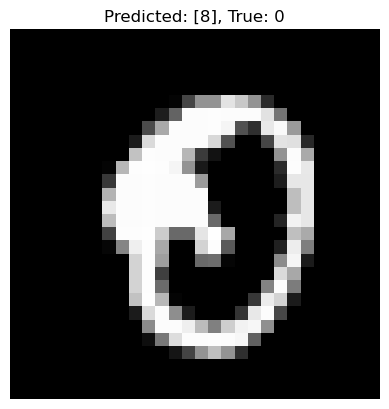

Misclassified index 4886: Predicted [1], True 7


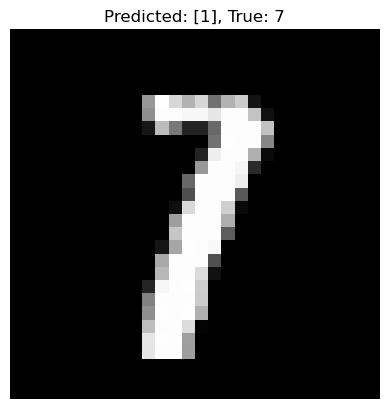

Misclassified index 4950: Predicted [3], True 2


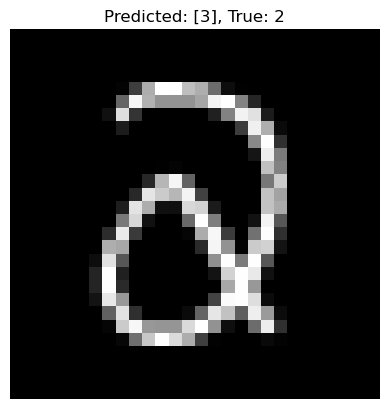

Misclassified index 4956: Predicted [4], True 8


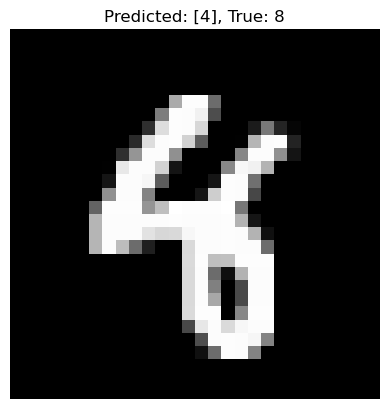

Misclassified index 4966: Predicted [9], True 7


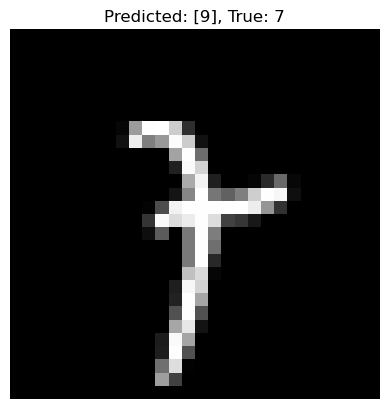

Misclassified index 4990: Predicted [8], True 3


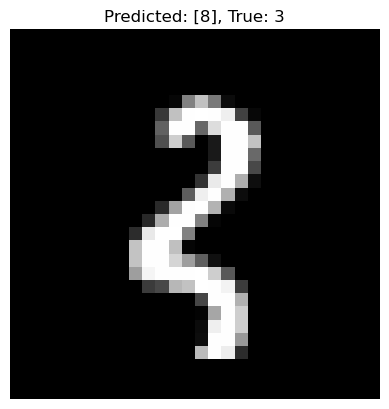

Misclassified index 5067: Predicted [2], True 3


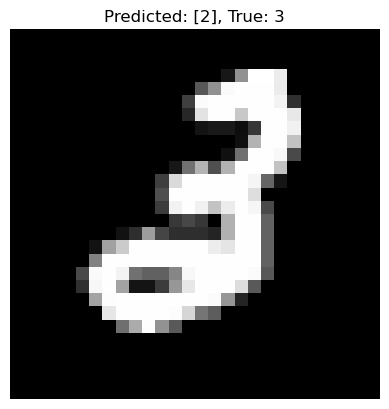

Misclassified index 5078: Predicted [2], True 3


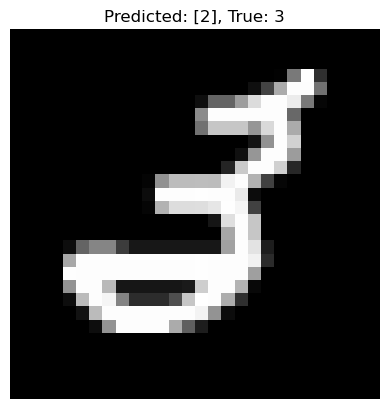

Misclassified index 5140: Predicted [5], True 3


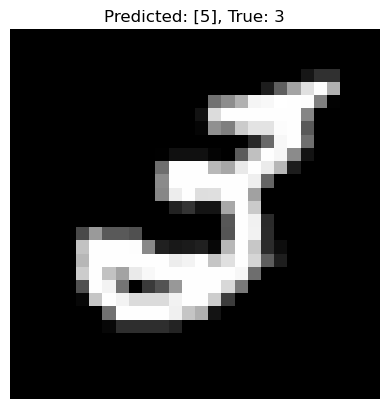

Misclassified index 5246: Predicted [2], True 7


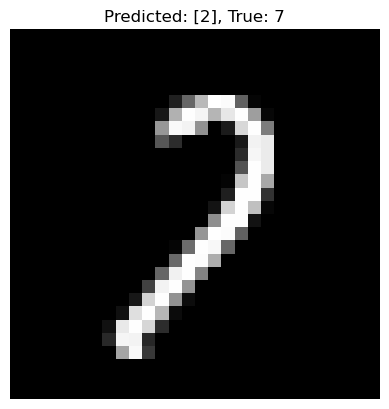

Misclassified index 5331: Predicted [6], True 1


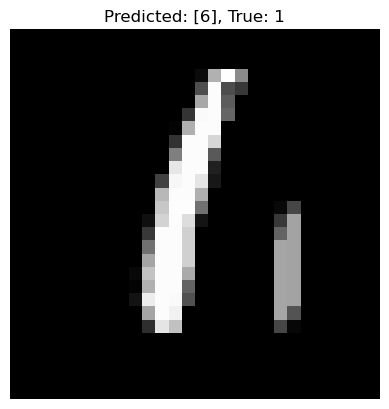

Misclassified index 5409: Predicted [6], True 4


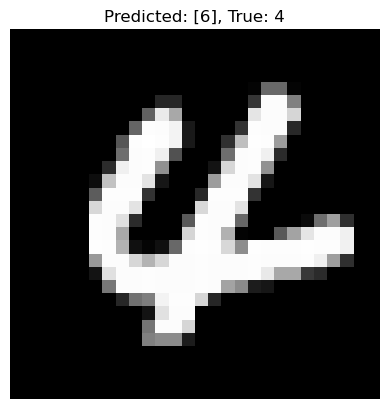

Misclassified index 5600: Predicted [9], True 7


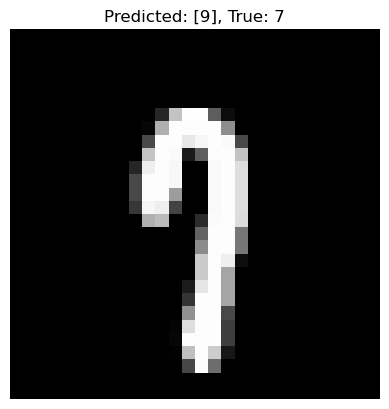

Misclassified index 5642: Predicted [5], True 1


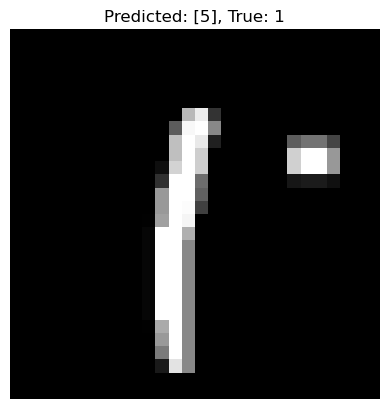

Misclassified index 5676: Predicted [3], True 4


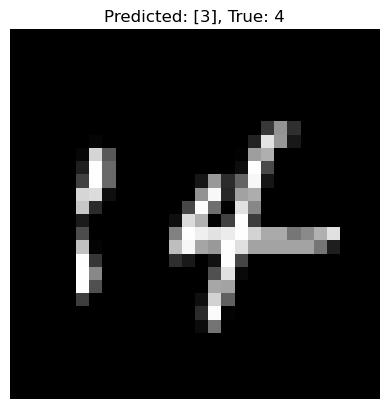

Misclassified index 5734: Predicted [9], True 3


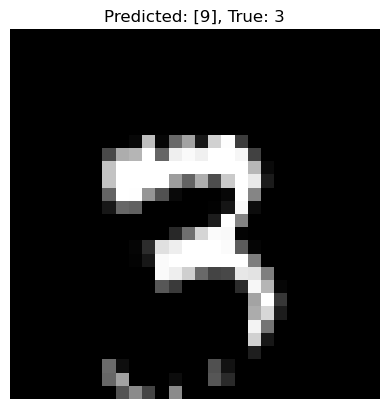

Misclassified index 5735: Predicted [6], True 5


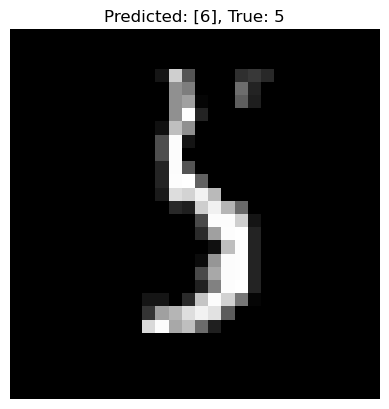

Misclassified index 5749: Predicted [2], True 8


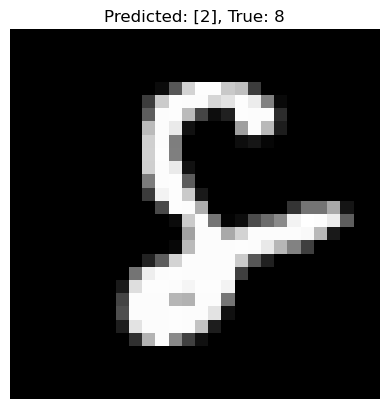

Misclassified index 5835: Predicted [8], True 7


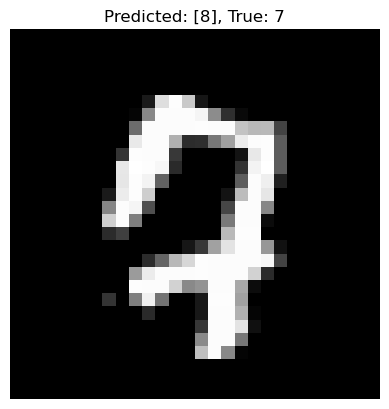

Misclassified index 5842: Predicted [7], True 4


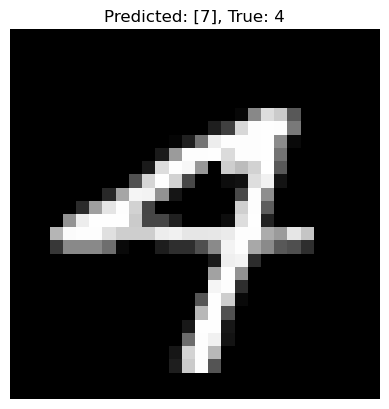

Misclassified index 5854: Predicted [4], True 7


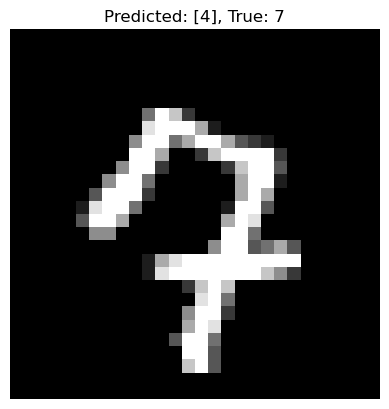

Misclassified index 5887: Predicted [0], True 7


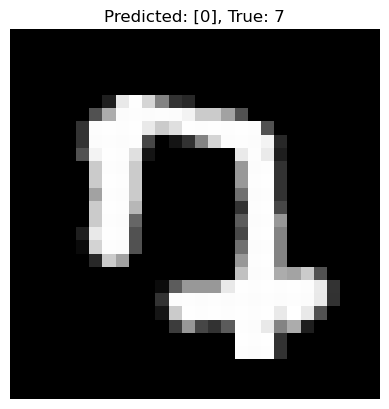

Misclassified index 5913: Predicted [3], True 5


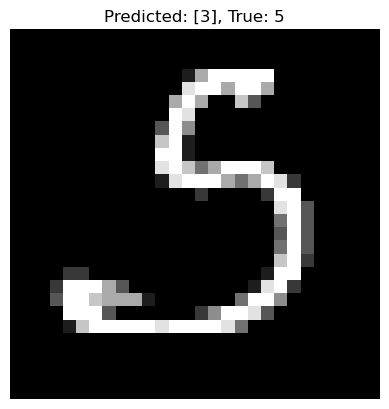

Misclassified index 5936: Predicted [9], True 4


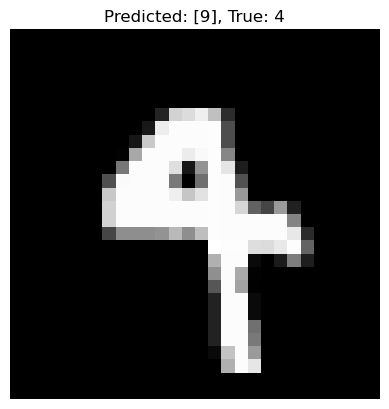

Misclassified index 5937: Predicted [3], True 5


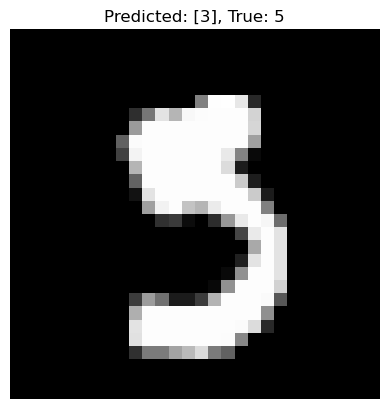

Misclassified index 5955: Predicted [9], True 3


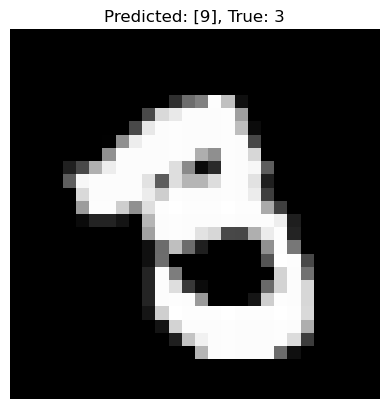

Misclassified index 5973: Predicted [9], True 3


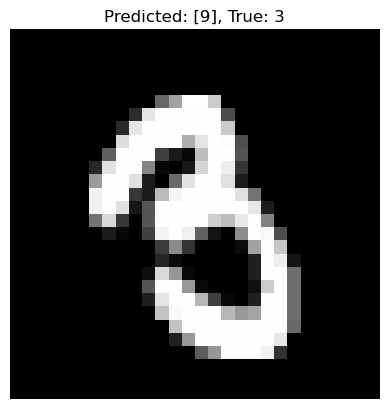

Misclassified index 5981: Predicted [9], True 5


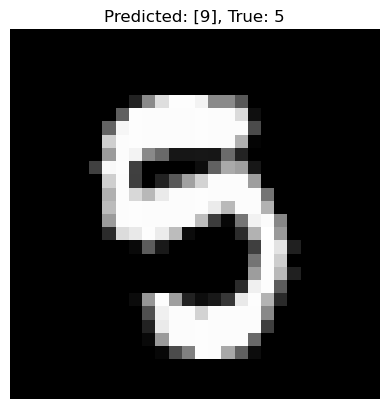

Misclassified index 5997: Predicted [9], True 5


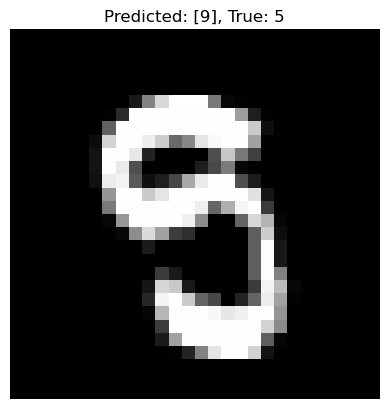

Misclassified index 6011: Predicted [0], True 3


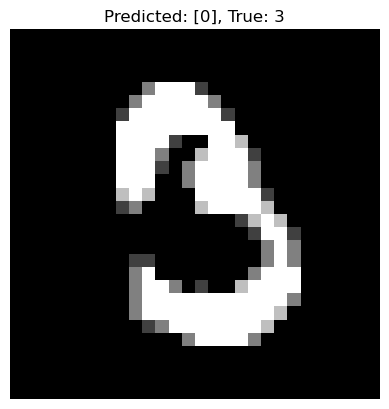

Misclassified index 6030: Predicted [9], True 3


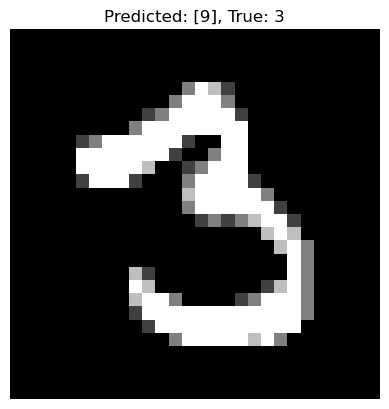

Misclassified index 6035: Predicted [0], True 2


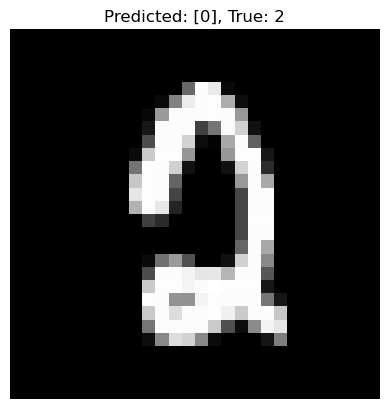

Misclassified index 6045: Predicted [9], True 3


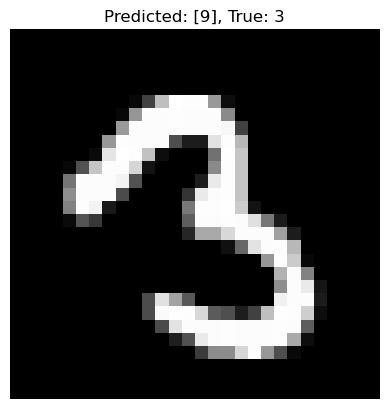

Misclassified index 6046: Predicted [8], True 3


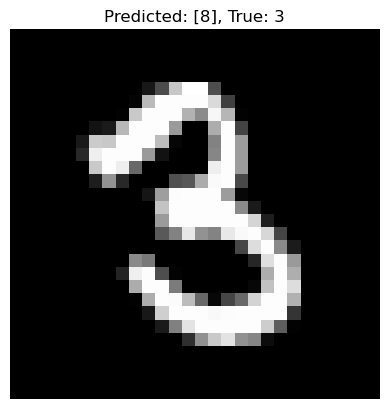

Misclassified index 6059: Predicted [9], True 3


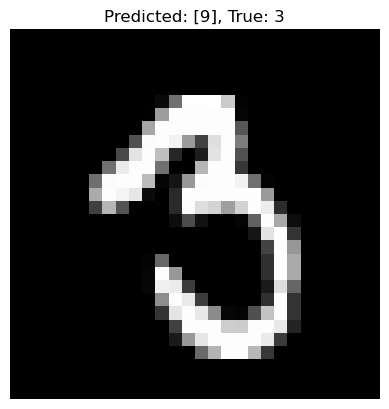

Misclassified index 6065: Predicted [8], True 3


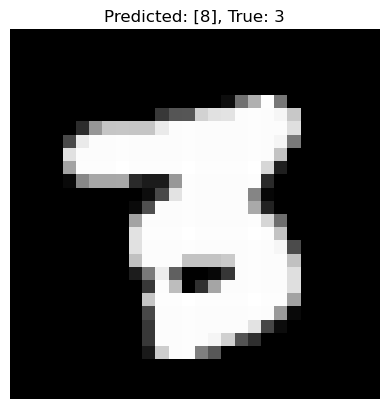

Misclassified index 6071: Predicted [3], True 9


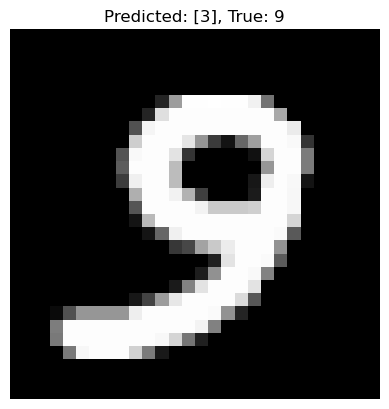

Misclassified index 6166: Predicted [3], True 9


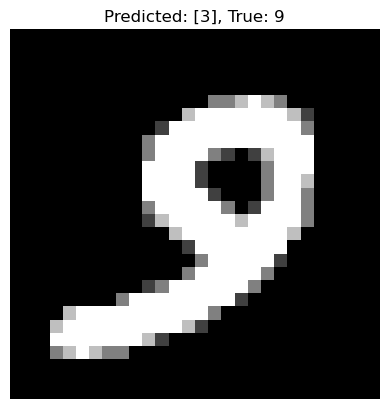

Misclassified index 6400: Predicted [6], True 0


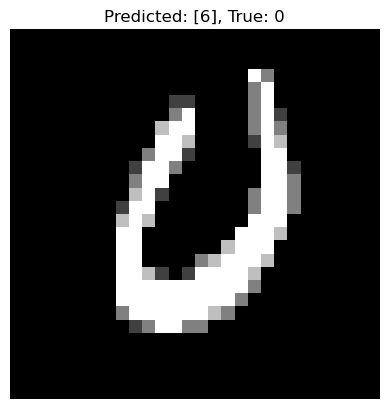

Misclassified index 6542: Predicted [4], True 3


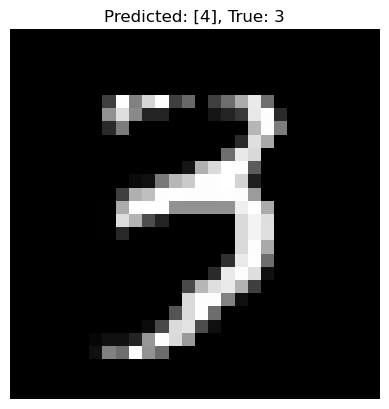

Misclassified index 6555: Predicted [9], True 8


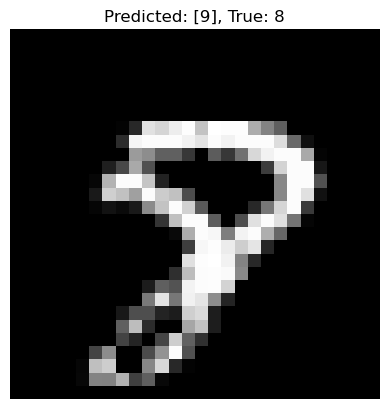

Misclassified index 6558: Predicted [2], True 6


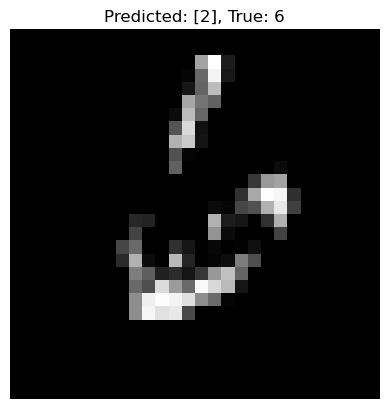

Misclassified index 6560: Predicted [3], True 9


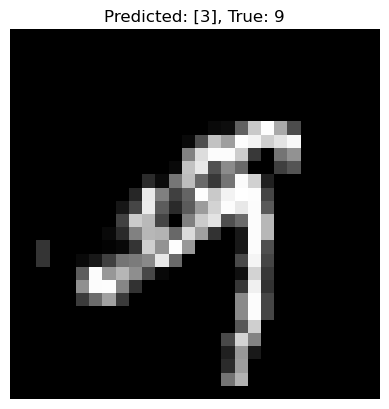

Misclassified index 6571: Predicted [7], True 9


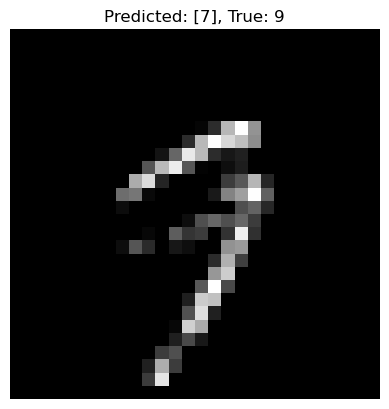

Misclassified index 6574: Predicted [6], True 2


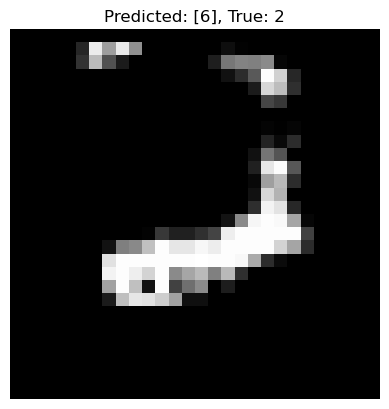

Misclassified index 6597: Predicted [7], True 0


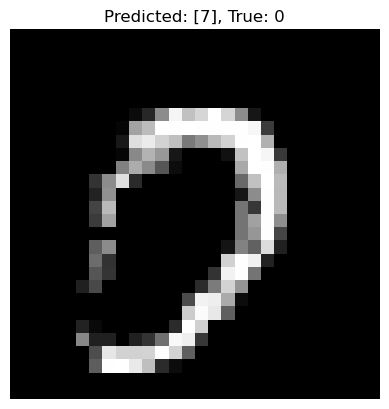

Misclassified index 6598: Predicted [3], True 5


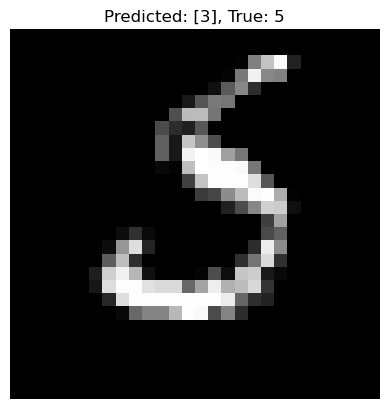

Misclassified index 6625: Predicted [7], True 8


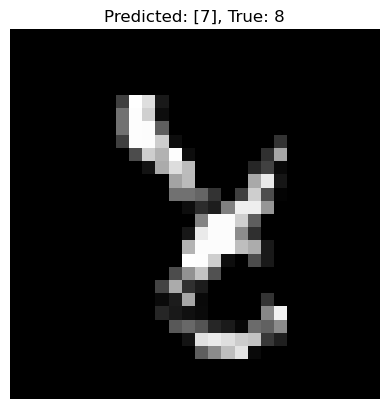

Misclassified index 6632: Predicted [5], True 9


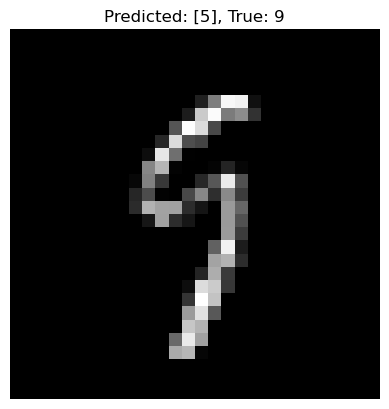

Misclassified index 6642: Predicted [4], True 9


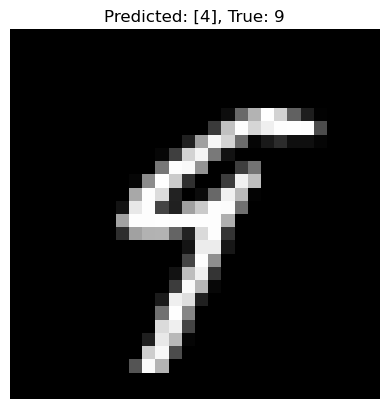

Misclassified index 6759: Predicted [6], True 4


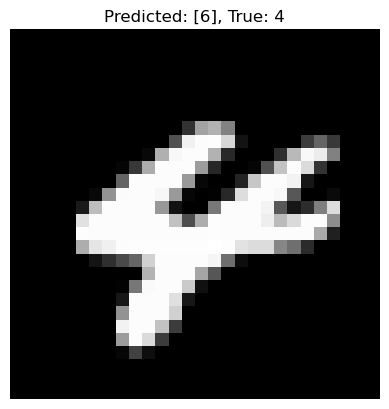

Misclassified index 6765: Predicted [6], True 8


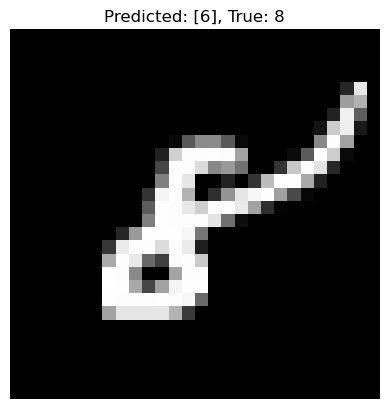

Misclassified index 6783: Predicted [6], True 1


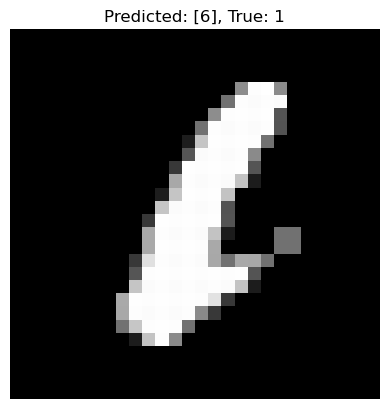

Misclassified index 6847: Predicted [4], True 6


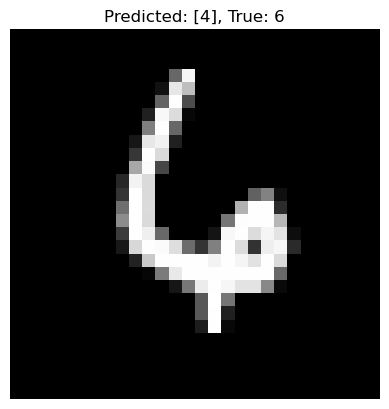

Misclassified index 6926: Predicted [4], True 6


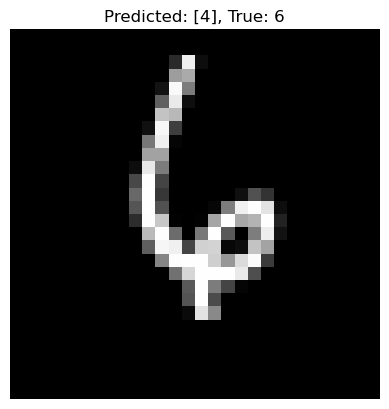

Misclassified index 7216: Predicted [6], True 0


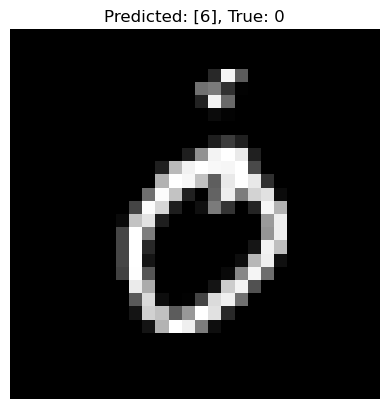

Misclassified index 7432: Predicted [1], True 7


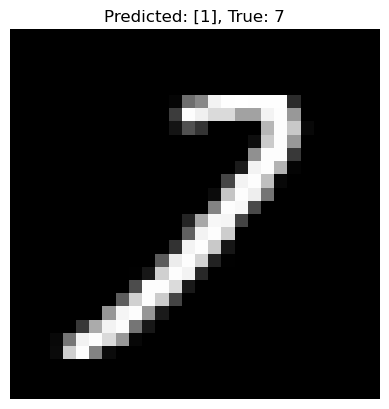

Misclassified index 7434: Predicted [9], True 4


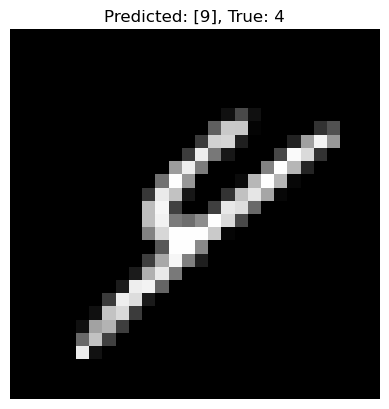

Misclassified index 7451: Predicted [6], True 5


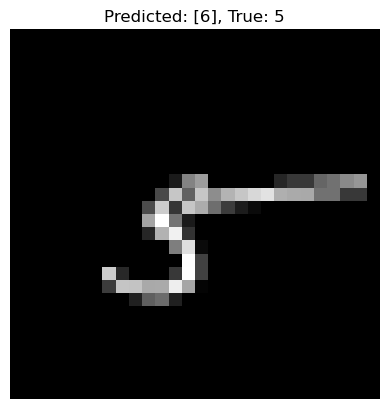

Misclassified index 7511: Predicted [3], True 5


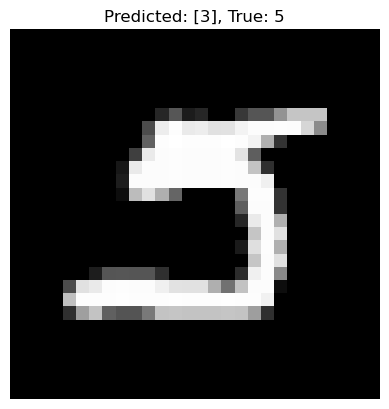

Misclassified index 7886: Predicted [4], True 2


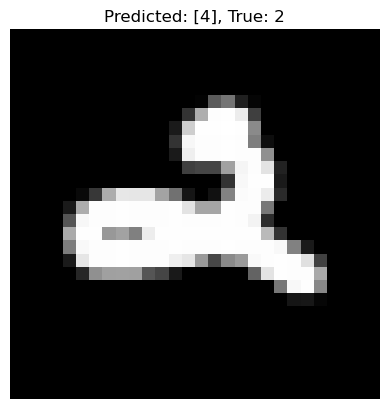

Misclassified index 7902: Predicted [8], True 7


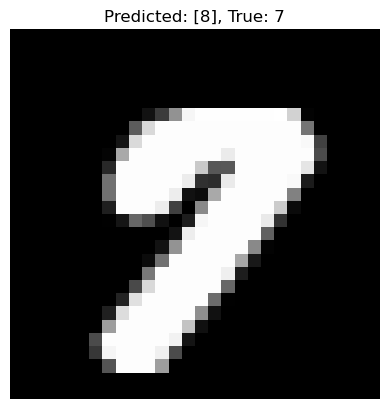

Misclassified index 7915: Predicted [8], True 7


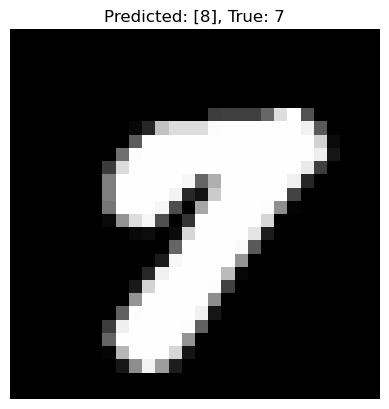

Misclassified index 7921: Predicted [6], True 8


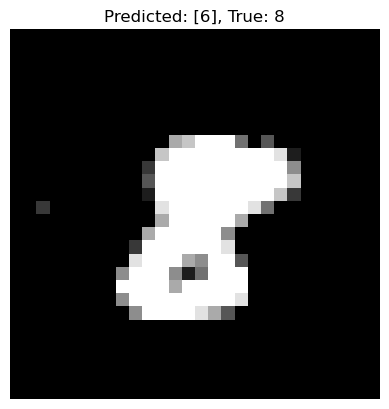

Misclassified index 8020: Predicted [8], True 1


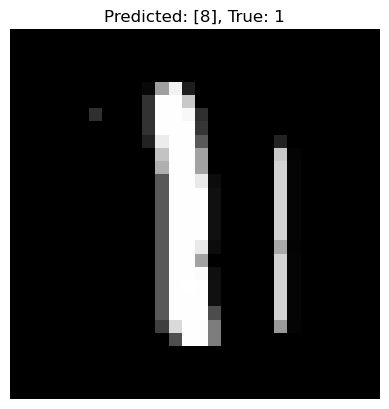

Misclassified index 8062: Predicted [8], True 5


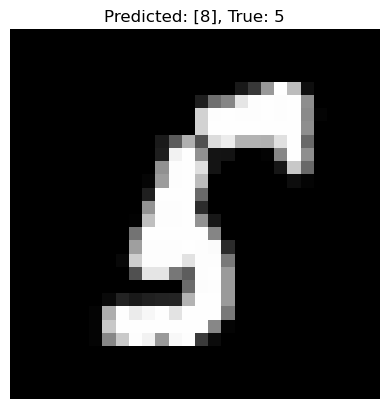

Misclassified index 8094: Predicted [8], True 2


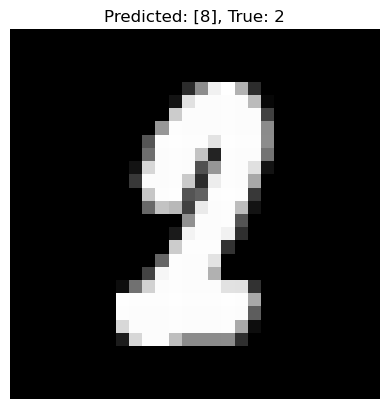

Misclassified index 8183: Predicted [5], True 8


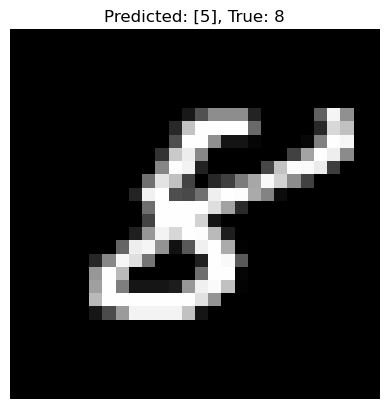

Misclassified index 8245: Predicted [9], True 2


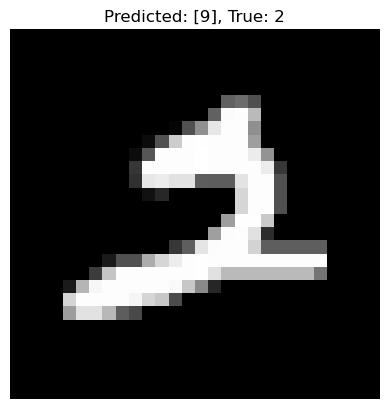

Misclassified index 8277: Predicted [9], True 3


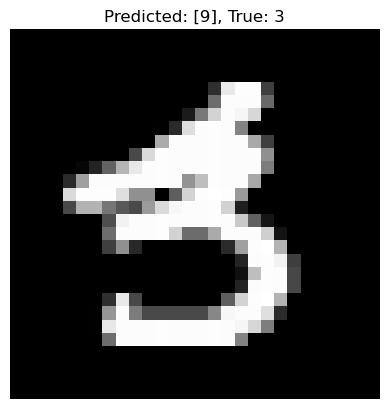

Misclassified index 8325: Predicted [3], True 0


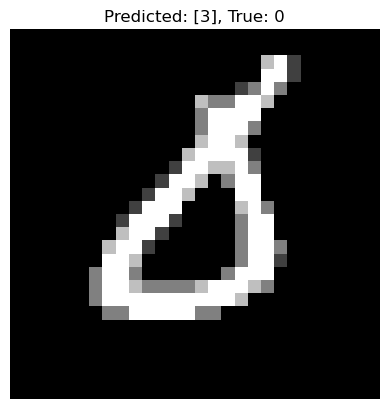

Misclassified index 8339: Predicted [6], True 8


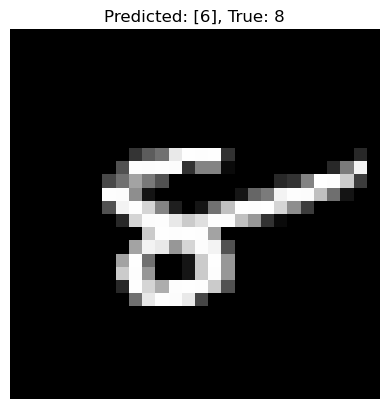

Misclassified index 8406: Predicted [9], True 4


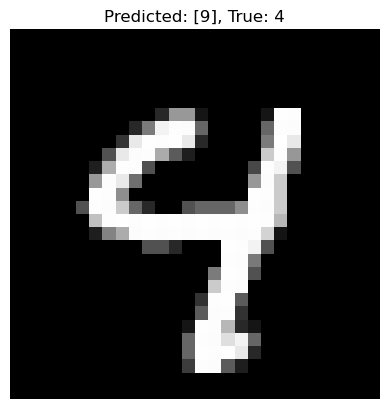

Misclassified index 8408: Predicted [6], True 8


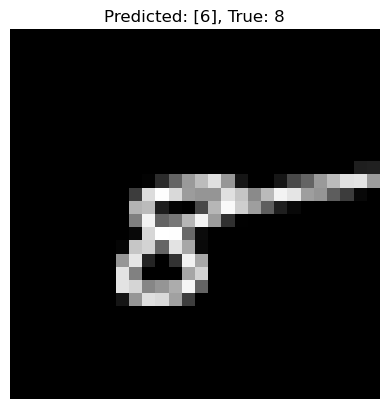

Misclassified index 8410: Predicted [6], True 8


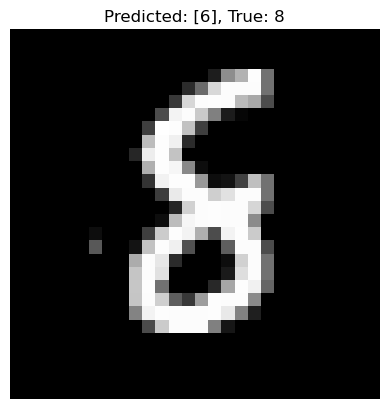

Misclassified index 8413: Predicted [5], True 8


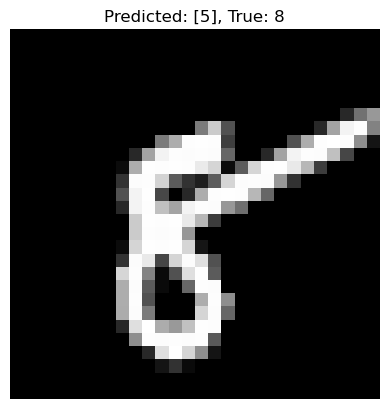

Misclassified index 8502: Predicted [3], True 5


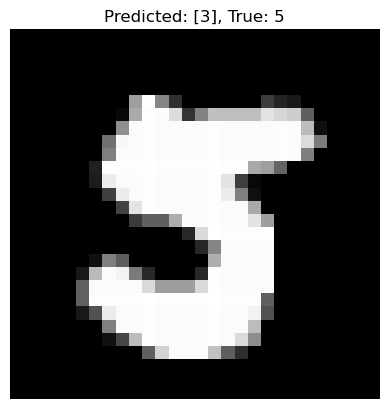

Misclassified index 8520: Predicted [9], True 4


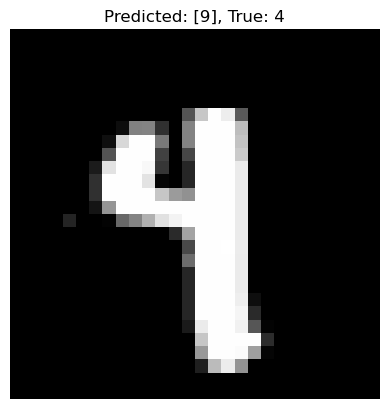

Misclassified index 8522: Predicted [6], True 8


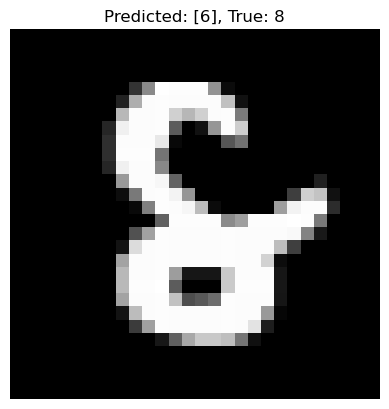

Misclassified index 8527: Predicted [9], True 4


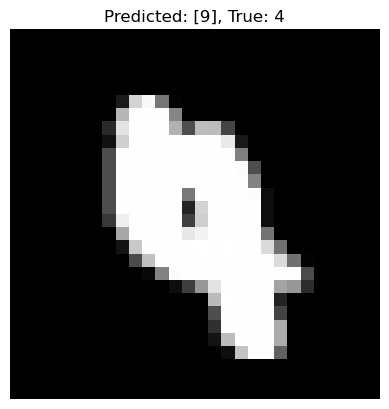

Misclassified index 8863: Predicted [6], True 5


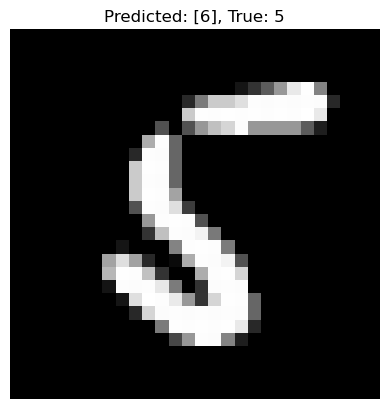

Misclassified index 9009: Predicted [2], True 7


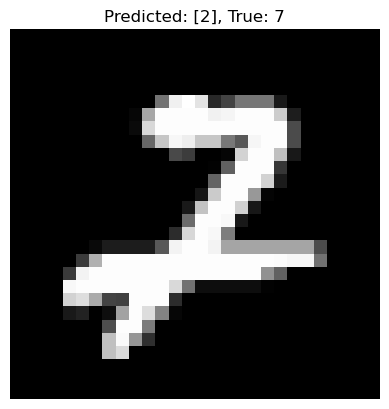

Misclassified index 9015: Predicted [2], True 7


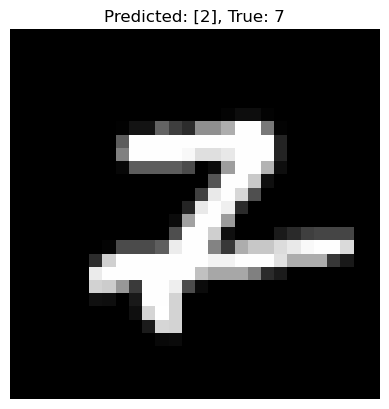

Misclassified index 9019: Predicted [2], True 7


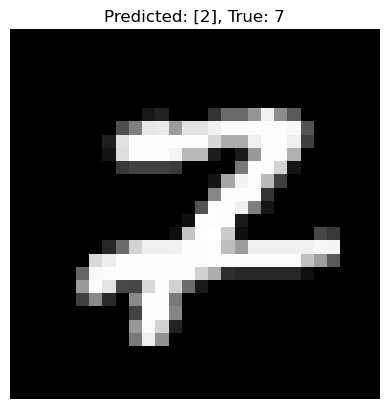

Misclassified index 9024: Predicted [2], True 7


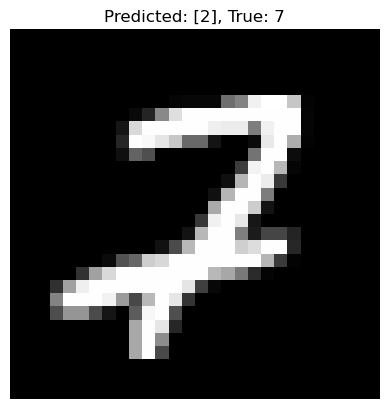

Misclassified index 9036: Predicted [2], True 7


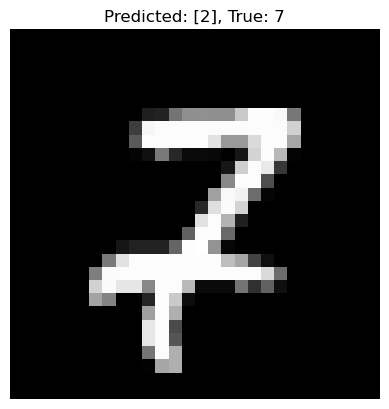

Misclassified index 9045: Predicted [2], True 7


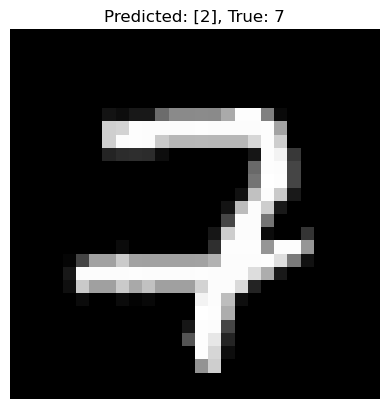

Misclassified index 9071: Predicted [8], True 1


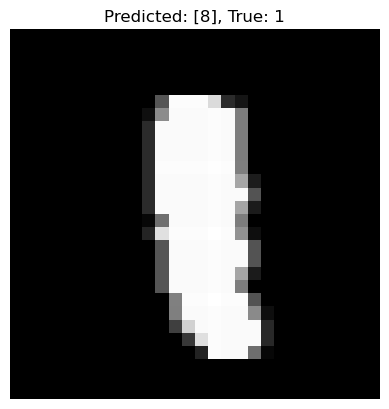

Misclassified index 9280: Predicted [5], True 8


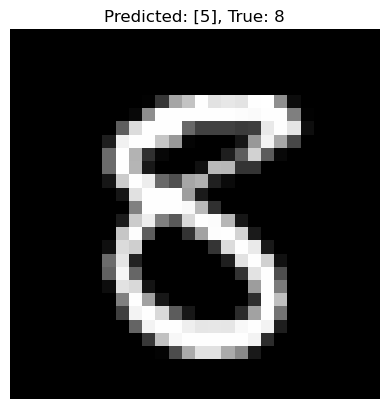

Misclassified index 9422: Predicted [3], True 5


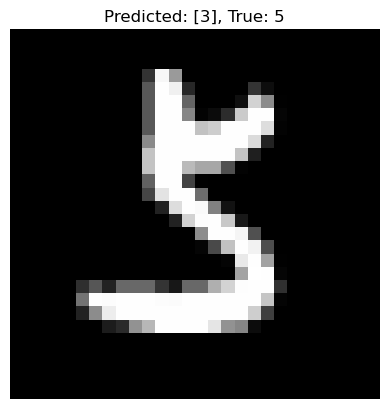

Misclassified index 9427: Predicted [3], True 5


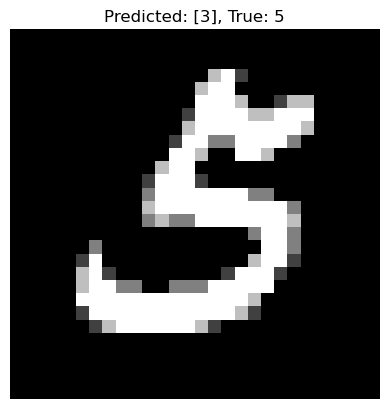

Misclassified index 9450: Predicted [6], True 8


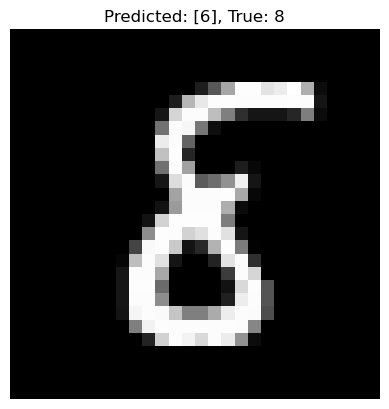

Misclassified index 9456: Predicted [7], True 2


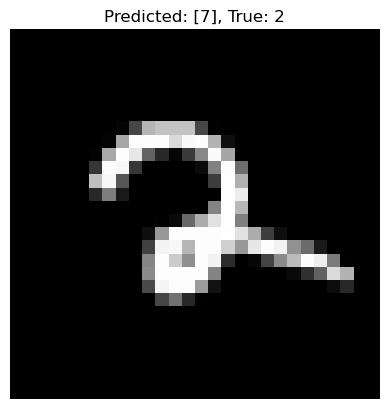

Misclassified index 9482: Predicted [3], True 5


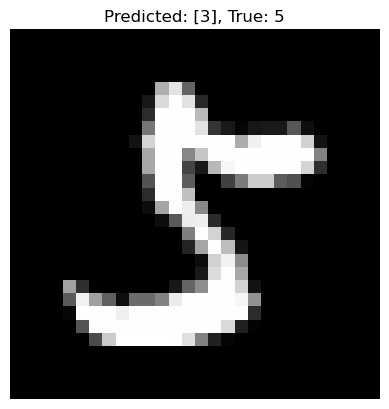

Misclassified index 9530: Predicted [8], True 9


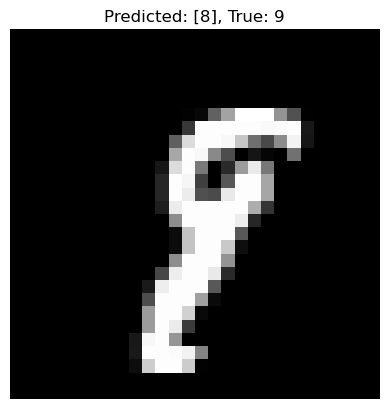

Misclassified index 9587: Predicted [4], True 9


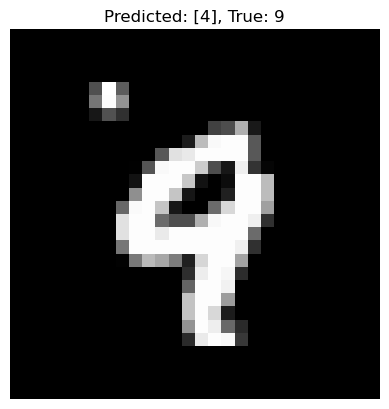

Misclassified index 9632: Predicted [2], True 6


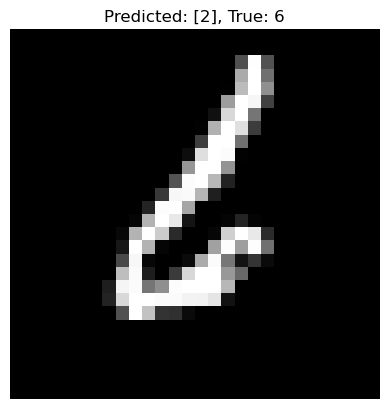

Misclassified index 9634: Predicted [3], True 0


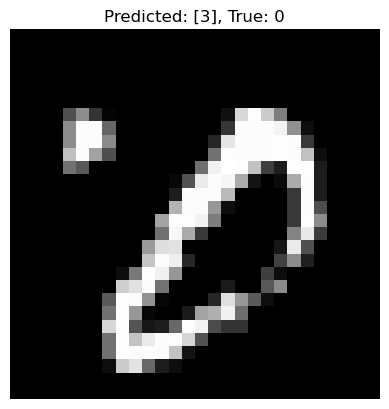

Misclassified index 9662: Predicted [2], True 3


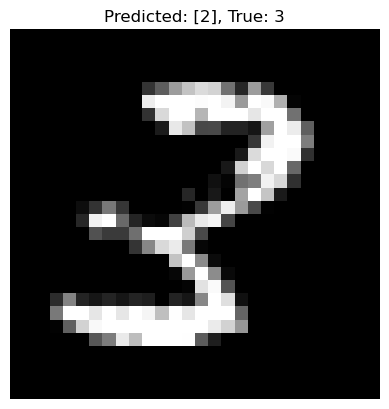

Misclassified index 9669: Predicted [9], True 4


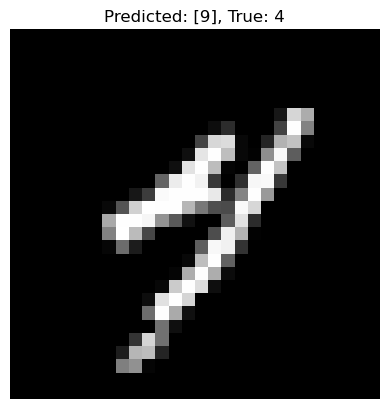

Misclassified index 9679: Predicted [3], True 6


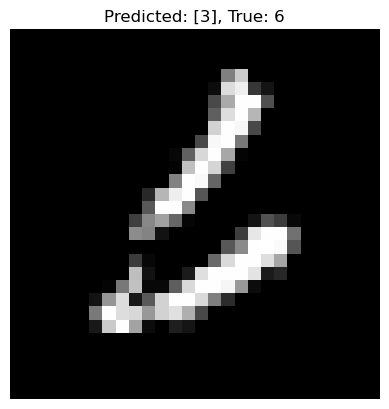

Misclassified index 9716: Predicted [3], True 2


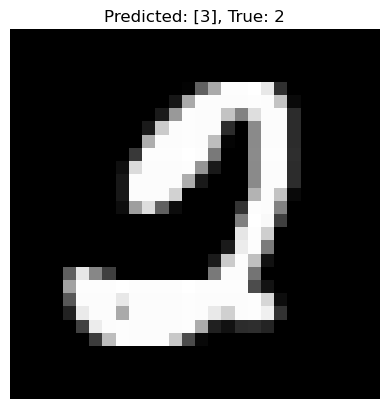

Misclassified index 9729: Predicted [6], True 5


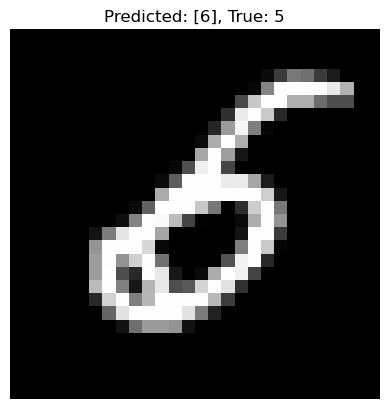

Misclassified index 9745: Predicted [0], True 4


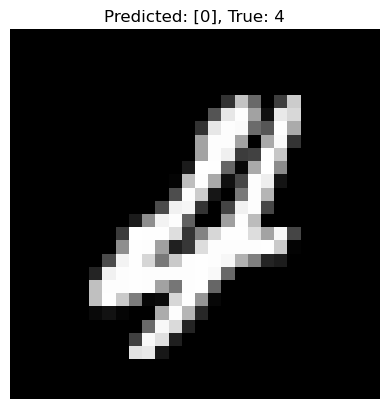

Misclassified index 9749: Predicted [6], True 5


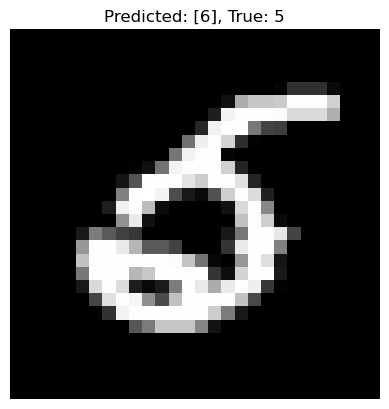

Misclassified index 9768: Predicted [0], True 2


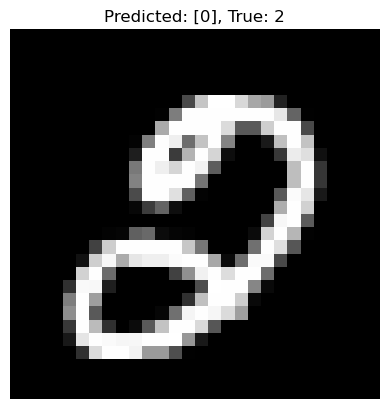

Misclassified index 9770: Predicted [0], True 5


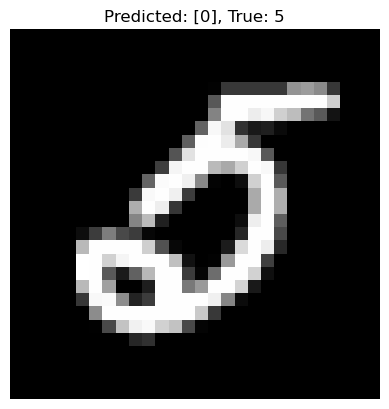

Misclassified index 9777: Predicted [0], True 5


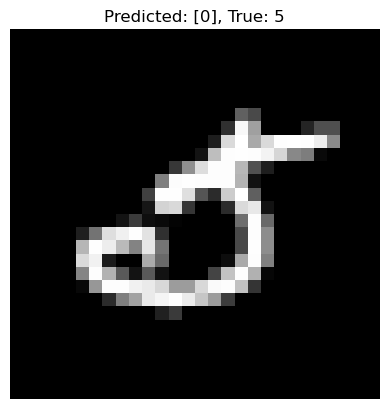

Misclassified index 9779: Predicted [0], True 2


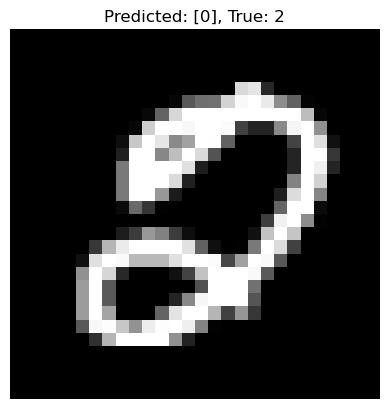

Misclassified index 9808: Predicted [4], True 9


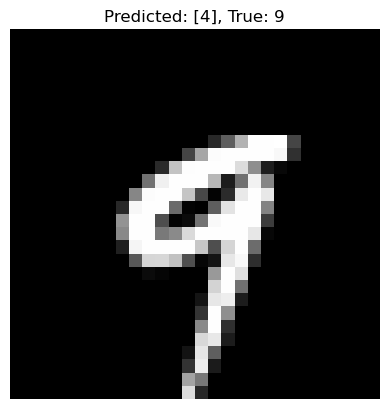

Misclassified index 9811: Predicted [8], True 2


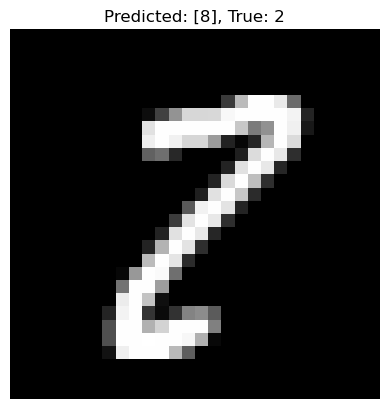

Misclassified index 9839: Predicted [7], True 2


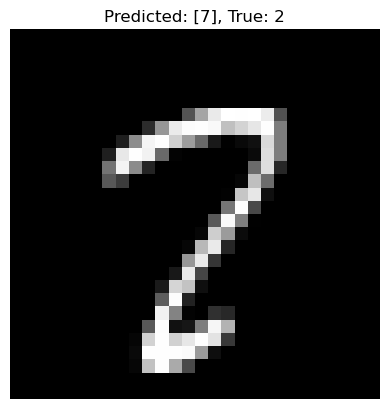

Misclassified index 9913: Predicted [8], True 2


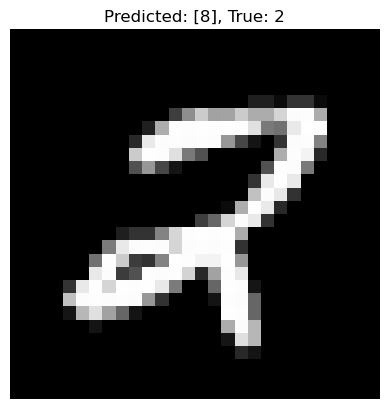

Misclassified index 9941: Predicted [6], True 5


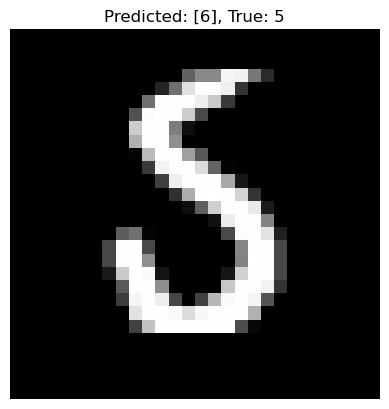

Misclassified index 9944: Predicted [8], True 3


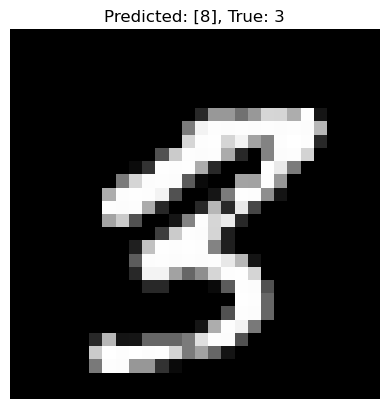

Misclassified index 9982: Predicted [6], True 5


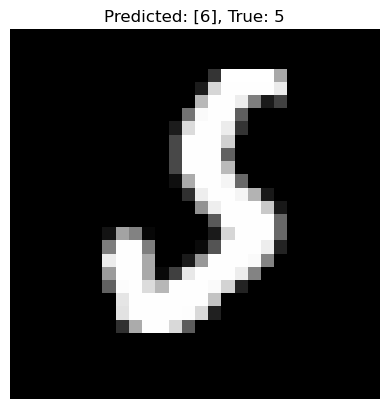

In [48]:
for i in range(len(images)):
    if all_preds[i] != all_targets[i]:
        print(f"Misclassified index {i}: Predicted {all_preds[i]}, True {all_targets[i]}")
        show_prediction(i)
       
